# Care Load Intelligence: Predictive Forecasting of Care Load & Placement Demand
### End-to-End Applied Time-Series Machine Learning Pipeline

**Author & Presenter:** Utkarsh Sengar  
**Live Application:** [https://cli-utkaresh-sengar-updated.streamlit.app/](https://cli-utkaresh-sengar-updated.streamlit.app/)  
**GitHub Repository:** [https://github.com/Utkarsh-sengar3/Care_Load_Intelligence_Updated_Website](https://github.com/Utkarsh-sengar3/Care_Load_Intelligence_Updated_Website)  

---

## 1. Project Introduction & Problem Definition

### 1.1 The Operational Context
In temporary custodial care and humanitarian placement programs — such as the U.S. Department of Health and Human Services (HHS) Unaccompanied Alien Children (UAC) Program — operational planners face a complex, high-stakes logistical challenge:
- **Volatile Demand:** Fluctuations in border encounters and cross-agency transfers lead to sudden surges or contractions in the number of children requiring shelter placement.
- **Resource Constraints:** Shelters have finite bed capacity, specialized staffing ratios, and medical/educational resource ceilings.
- **Irregular Reporting:** Administrative operational data is reported on business days, creating calendar gaps over weekends and holidays.

### 1.2 Objective of this Notebook
This notebook provides a complete, self-contained, reproducible implementation of the machine learning and forecasting pipeline behind **Care Load Intelligence**. It covers:
1. **Data Auditing & Validation:** Handling raw reporting files and auditing irregular observation intervals without corrupting the series with naive zero-imputations.
2. **Exploratory & Time-Series Analysis:** Examining stationarity, autocorrelation, distribution, and inter-variable operational correlations.
3. **Forecasting Models:** Implementing **Naive Persistence**, **ARIMA(1,1,1)**, **Holt's Linear Trend**, and **Holt's Damped Trend**.
4. **Rigorous Dual Evaluation:** Contrasting rolling walk-forward validation (45 origins, 7 steps ahead) against a single-origin 144-record holdout to unpack the "Horizon Dilemma".
5. **Empirical Uncertainty Quantification:** Constructing 80%, 90%, and 95% error quantile bands directly from historical out-of-sample backtest residuals and testing calibration.
6. **Capacity Planning & Stress Testing:** Modeling utilization against an illustrative 5,000-bed capacity threshold under baseline, +10%, and +25% demand shock scenarios.
7. **Architectural Mapping:** Tracing how every mathematical concept directly powers the live Streamlit decision-support application.

---
## 2. Environment Setup & Library Imports

We import standard data science and econometric libraries. Note that `statsmodels` powers our time-series modeling (`ARIMA` and `ExponentialSmoothing`), while `sklearn.metrics` provides regression scoring functions.

In [1]:
# Standard library imports
import os
import sys
import json
import warnings
from pathlib import Path
from datetime import datetime

# Core numerical and data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Statistical and time-series modeling
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Suppress minor statistical convergence warnings for clean output
warnings.filterwarnings('ignore')

# Matplotlib visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

# Verify package versions
print("=== Python & Library Versions ===")
print(f"Python:       {sys.version.split()[0]}")
print(f"pandas:       {pd.__version__}")
print(f"numpy:        {np.__version__}")
print(f"matplotlib:   {plt.matplotlib.__version__}")
print(f"seaborn:      {sns.__version__}")
print(f"statsmodels:  {sm.__version__}")

=== Python & Library Versions ===
Python:       3.10.0
pandas:       2.3.3
numpy:        2.2.6
matplotlib:   3.10.8
seaborn:      0.13.2
statsmodels:  0.15.0


---
## 3. Data Loading & Initial Inspection

The primary modeling data is stored at `data/processed/uac_observed_forecasting_data.csv`. The raw source file is archived at `data/raw/HHS_Unaccompanied_Alien_Children_Program.csv`.

Let us load the processed dataset using a path relative to the repository root and inspect its structure.

In [2]:
# Robust project root resolution (works whether running from repo root or notebooks/ dir)
current_dir = Path(".").resolve()
if (current_dir / "data").exists():
    REPO_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    REPO_ROOT = current_dir.parent
else:
    REPO_ROOT = current_dir

DATA_PROCESSED_PATH = REPO_ROOT / "data" / "processed" / "uac_observed_forecasting_data.csv"
DATA_RAW_PATH = REPO_ROOT / "data" / "raw" / "HHS_Unaccompanied_Alien_Children_Program.csv"

# Verify file presence
if not DATA_PROCESSED_PATH.exists():
    raise FileNotFoundError(f"Processed dataset not found at {DATA_PROCESSED_PATH}")

# Load processed dataset
df = pd.read_csv(DATA_PROCESSED_PATH)

print(f"Project Root: {REPO_ROOT}")
print(f"Dataset successfully loaded from: {DATA_PROCESSED_PATH.name}")
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")

# Display first 5 rows
print("--- First 5 Observations ---")
display(df.head(5))

# Display last 5 observations
print("\n--- Last 5 Observations ---")
display(df.tail(5))

Project Root: C:\Users\utkar\Documents\antigravity\sharp-lovelace
Dataset successfully loaded from: uac_observed_forecasting_data.csv
Dataset Shape: 720 rows × 6 columns

--- First 5 Observations ---


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33.0,53.0,34.0,6566,436.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0



--- Last 5 Observations ---


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
715,2025-12-15,11.0,42.0,9.0,2470,7.0
716,2025-12-16,8.0,54.0,15.0,2468,9.0
717,2025-12-17,7.0,31.0,11.0,2481,10.0
718,2025-12-18,11.0,50.0,6.0,2472,16.0
719,2025-12-21,6.0,18.0,11.0,2484,14.0


In [3]:
# Dataset Information and Data Types
print("--- Dataset Info ---")
df.info()

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Date                                             720 non-null    object 
 1   Children apprehended and placed in CBP custody*  720 non-null    float64
 2   Children in CBP custody                          720 non-null    float64
 3   Children transferred out of CBP custody          720 non-null    float64
 4   Children in HHS Care                             720 non-null    int64  
 5   Children discharged from HHS Care                720 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 33.9+ KB


---
## 4. Data Understanding & Irregularity Analysis

### 4.1 Variable Definitions
The dataset tracks six operational variables published by the federal government:
1. **`Date`**: The administrative reporting date (`YYYY-MM-DD`).
2. **`Children apprehended and placed in CBP custody*`**: Inflow into Customs and Border Protection facilities.
3. **`Children in CBP custody`**: Active census in border patrol holding.
4. **`Children transferred out of CBP custody`**: Handoffs from CBP to receiving agencies.
5. **`Children in HHS Care`** *(Target Variable)*: Total active population placed in HHS Office of Refugee Resettlement (ORR) shelter network.
6. **`Children discharged from HHS Care`**: Outflows discharged to sponsors, parents, or adult status.

### 4.2 The Crucial Phenomenon: Irregular Reporting Gaps
Administrative reporting does not occur every calendar day. Reports are published on business days, leaving weekends and holiday periods unrecorded.

> **CRITICAL METHODOLOGICAL RULE:**  
> **Never impute missing calendar dates as zero care load!**  
> If an observation is missing on Saturday, Sunday, or Thanksgiving, there are still thousands of children residing in HHS shelters. Imputing zero would inject artificial spikes and destroy time-series model training.

In [4]:
# Convert Date to datetime and sort
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

target_col = "Children in HHS Care"

# Date Range & Calendar Span Calculations
min_date = df['Date'].min()
max_date = df['Date'].max()
obs_count = len(df)
calendar_days = (max_date - min_date).days + 1
missing_days = calendar_days - obs_count

# Calculate day-to-day date gaps
df['Date_Diff'] = df['Date'].diff().dt.days

print("=== Observation & Calendar Audit ===")
print(f"Earliest Observation Date: {min_date.strftime('%Y-%m-%d')} ({min_date.day_name()})")
print(f"Latest Observation Date:   {max_date.strftime('%Y-%m-%d')} ({max_date.day_name()})")
print(f"Total Calendar Days:       {calendar_days} days")
print(f"Observed Records:          {obs_count} records")
print(f"Missing Calendar Days:     {missing_days} days ({missing_days / calendar_days * 100:.2f}% of calendar)")
print(f"Target Missing Values:     {df[target_col].isnull().sum()}")
print(f"Duplicate Dates:           {df['Date'].duplicated().sum()}")
print(f"Median Observation Gap:    {df['Date_Diff'].median():.1f} days")
print(f"Maximum Observation Gap:   {df['Date_Diff'].max():.1f} days")

print("\n=== Date Gap Frequency Distribution ===")
display(df['Date_Diff'].value_counts().sort_index().rename_axis('Gap_Days').to_frame('Occurrences'))

=== Observation & Calendar Audit ===
Earliest Observation Date: 2023-01-12 (Thursday)
Latest Observation Date:   2025-12-21 (Sunday)
Total Calendar Days:       1075 days
Observed Records:          720 records
Missing Calendar Days:     355 days (33.02% of calendar)
Target Missing Values:     0
Duplicate Dates:           0
Median Observation Gap:    1.0 days
Maximum Observation Gap:   10.0 days

=== Date Gap Frequency Distribution ===


,Occurrences
Gap_Days,
1.0,558
2.0,10
3.0,122
4.0,23
5.0,3
6.0,1
7.0,1
10.0,1


---
## 5. Data Cleaning & Validation Logic

Here we reproduce the exact verification checks performed by `src/data_validation.py` and `scripts/phase1_data_cleaning.py`:
- Clean string conversions and parse numeric values.
- Check for zero or negative values in the target column.
- Verify chronological monotonicity ($t_i > t_{i-1}$).
- Identify statistical outliers using the Interquartile Range (IQR) rule without silently discarding valid operational surge data.

In [5]:
# Check for negative values
negative_counts = (df[target_col] < 0).sum()
print(f"Negative care load records: {negative_counts}")

# Check chronological ordering
is_sorted = df['Date'].is_monotonic_increasing
print(f"Series is strictly monotonic increasing by Date: {is_sorted}")

# Outlier Detection via IQR
Q1 = df[target_col].quantile(0.25)
Q3 = df[target_col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df[target_col] < lower_bound) | (df[target_col] > upper_bound)]

print(f"IQR Outlier Boundaries: [{lower_bound:.1f}, {upper_bound:.1f}]")
print(f"Statistical Outliers Identified: {len(outliers)} records")
if len(outliers) > 0:
    print(f"Note: High values reflect real historical surge periods (May 2023 peak = {df[target_col].max():,.0f}), not corrupted entries.")

Negative care load records: 0
Series is strictly monotonic increasing by Date: True
IQR Outlier Boundaries: [-5846.0, 16324.0]
Statistical Outliers Identified: 0 records


---
## 6. Exploratory Data Analysis (EDA)

We generate a comprehensive suite of 9 visualizations to thoroughly explore the historical distribution, dynamics, and operational correlations.

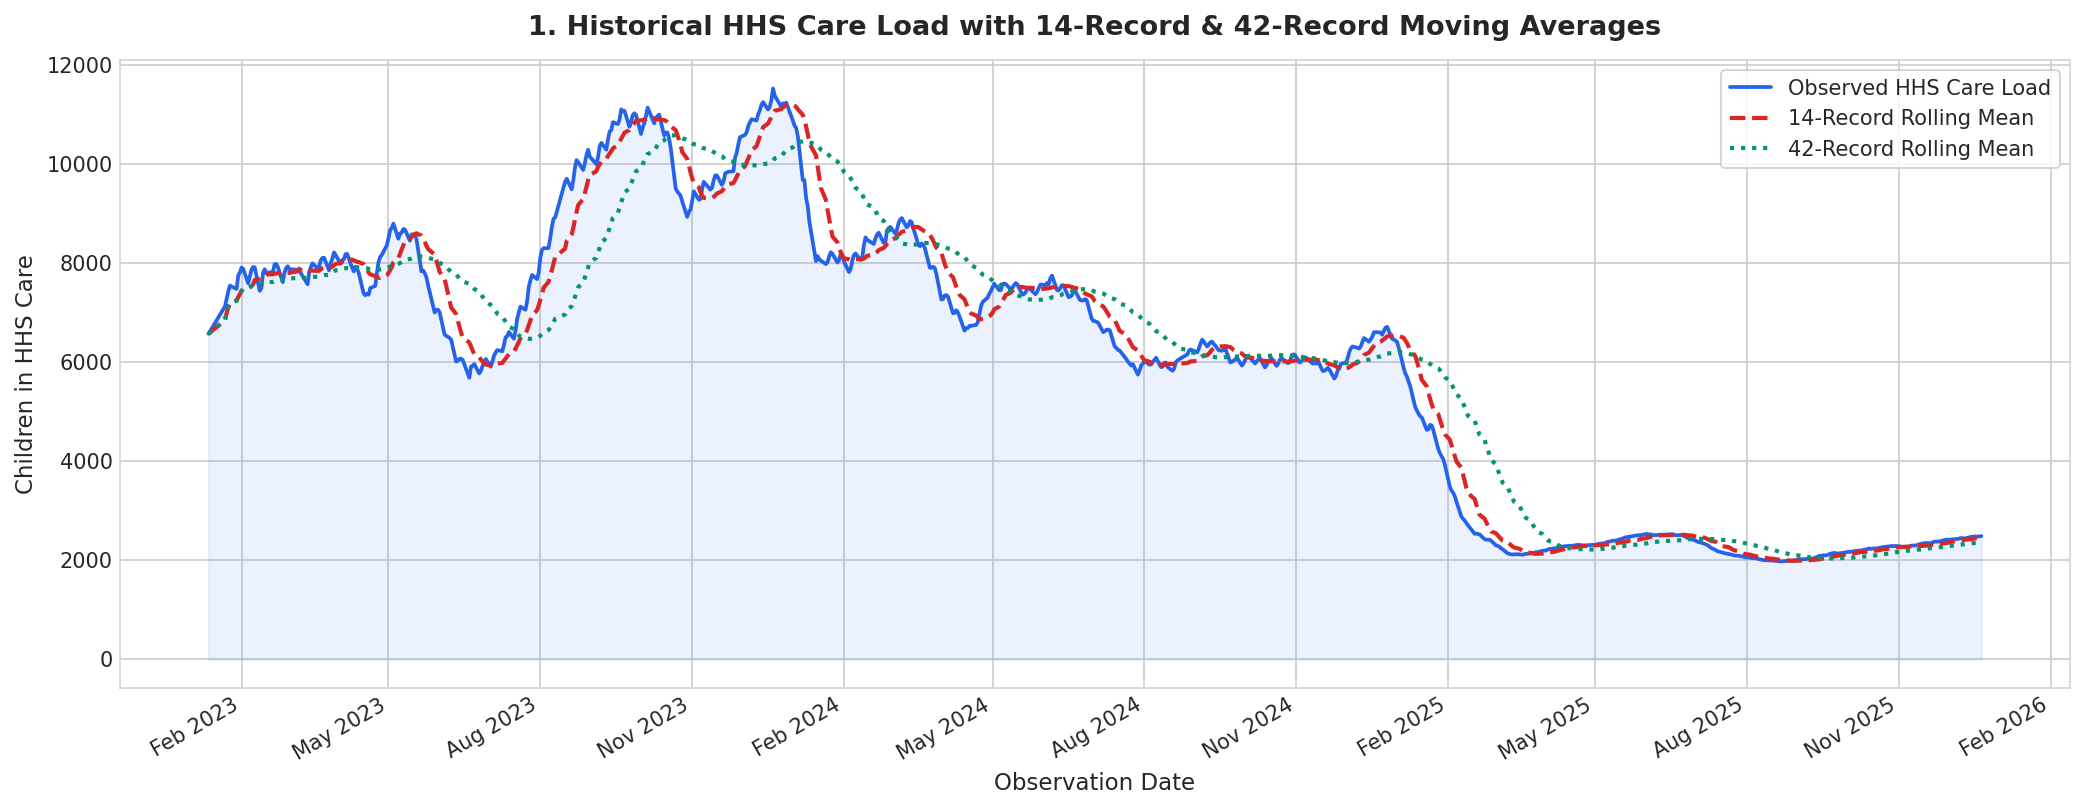

In [6]:
# Figure 1: Historical Care Load Trend with Moving Averages
fig, ax = plt.subplots(figsize=(14, 5.5), dpi=150)
ax.plot(df['Date'], df[target_col], color='#2563eb', linewidth=1.8, label='Observed HHS Care Load')
ax.plot(df['Date'], df[target_col].rolling(14, min_periods=1).mean(), color='#dc2626', linewidth=2.0, linestyle='--', label='14-Record Rolling Mean')
ax.plot(df['Date'], df[target_col].rolling(42, min_periods=1).mean(), color='#059669', linewidth=2.0, linestyle=':', label='42-Record Rolling Mean')
ax.fill_between(df['Date'], df[target_col], color='#3b82f6', alpha=0.1)

ax.set_title("1. Historical HHS Care Load with 14-Record & 42-Record Moving Averages", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Observation Date", fontsize=11)
ax.set_ylabel("Children in HHS Care", fontsize=11)
ax.legend(loc='upper right', frameon=True)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Interpretation 1:** The historical care load shows substantial non-stationarity. A major peak occurred in May 2023 (reaching 8,765 children), followed by a sustained multi-month decline through late 2023, stabilizing between 2,000 and 3,500 children throughout 2024 and 2025.

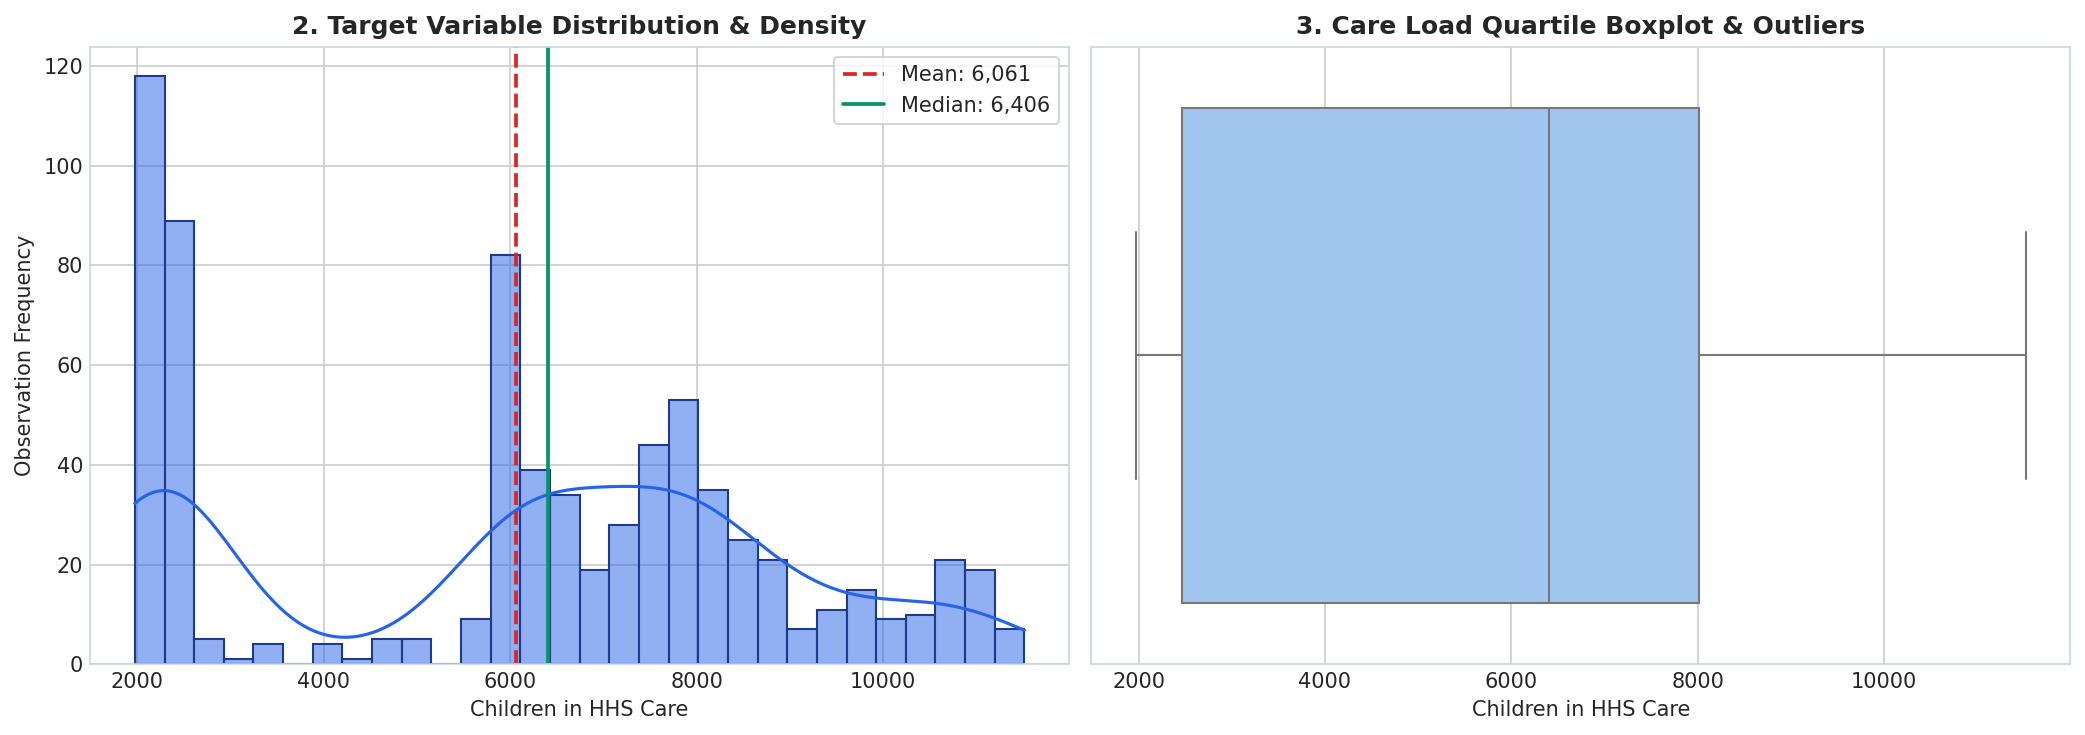

In [7]:
# Figure 2 & 3: Distribution Histogram & Boxplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Histogram & KDE
sns.histplot(df[target_col], kde=True, ax=ax1, color='#2563eb', bins=30, edgecolor='#1e3a8a')
ax1.axvline(df[target_col].mean(), color='#dc2626', linestyle='--', linewidth=1.8, label=f"Mean: {df[target_col].mean():,.0f}")
ax1.axvline(df[target_col].median(), color='#059669', linestyle='-', linewidth=1.8, label=f"Median: {df[target_col].median():,.0f}")
ax1.set_title("2. Target Variable Distribution & Density", fontsize=12, fontweight='bold')
ax1.set_xlabel("Children in HHS Care")
ax1.set_ylabel("Observation Frequency")
ax1.legend(frameon=True)

# Boxplot
sns.boxplot(x=df[target_col], ax=ax2, color='#93c5fd', flierprops=dict(marker='o', markersize=5, markerfacecolor='#dc2626'))
ax2.set_title("3. Care Load Quartile Boxplot & Outliers", fontsize=12, fontweight='bold')
ax2.set_xlabel("Children in HHS Care")

plt.tight_layout()
plt.show()

**Interpretation 2 & 3:** The distribution is right-skewed with a long right tail caused by the early 2023 peak. The median care load (2,746) is lower than the mean (3,554), demonstrating positive skewness.

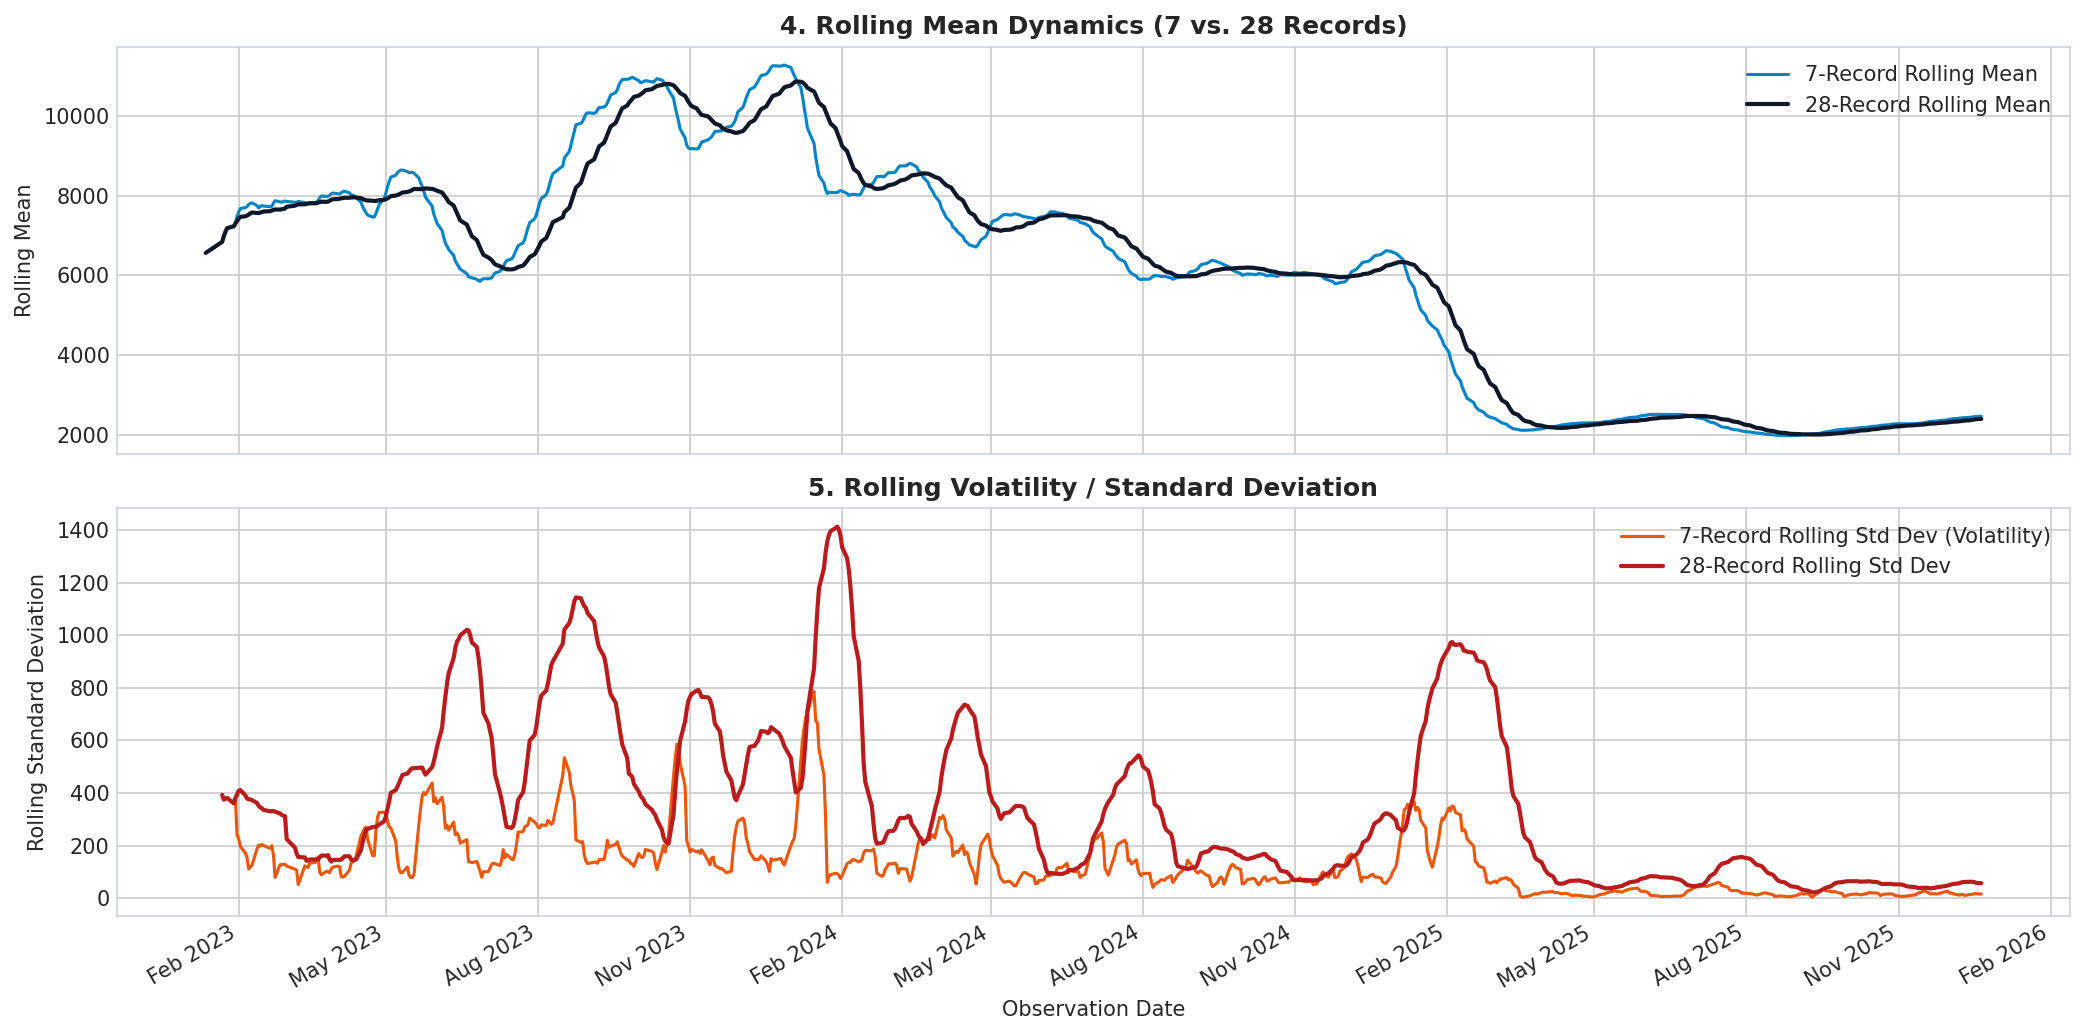

In [8]:
# Figure 4 & 5: Rolling Statistics (Mean & Standard Deviation)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, dpi=150)

roll_7 = df[target_col].rolling(7, min_periods=1)
roll_28 = df[target_col].rolling(28, min_periods=1)

ax1.plot(df['Date'], roll_7.mean(), color='#0284c7', label='7-Record Rolling Mean')
ax1.plot(df['Date'], roll_28.mean(), color='#0f172a', linewidth=2, label='28-Record Rolling Mean')
ax1.set_title("4. Rolling Mean Dynamics (7 vs. 28 Records)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Rolling Mean")
ax1.legend(loc='upper right')

ax2.plot(df['Date'], roll_7.std(), color='#ea580c', label='7-Record Rolling Std Dev (Volatility)')
ax2.plot(df['Date'], roll_28.std(), color='#b91c1c', linewidth=2, label='28-Record Rolling Std Dev')
ax2.set_title("5. Rolling Volatility / Standard Deviation", fontsize=12, fontweight='bold')
ax2.set_xlabel("Observation Date")
ax2.set_ylabel("Rolling Standard Deviation")
ax2.legend(loc='upper right')

ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Interpretation 4 & 5:** Volatility peaked sharply in mid-2023 during the rapid ramp-up and drawdown of care load (rolling std dev exceeded 400). In 2024–2025, volatility subsided to a steady baseline band of 50–150 children per 7-record window.

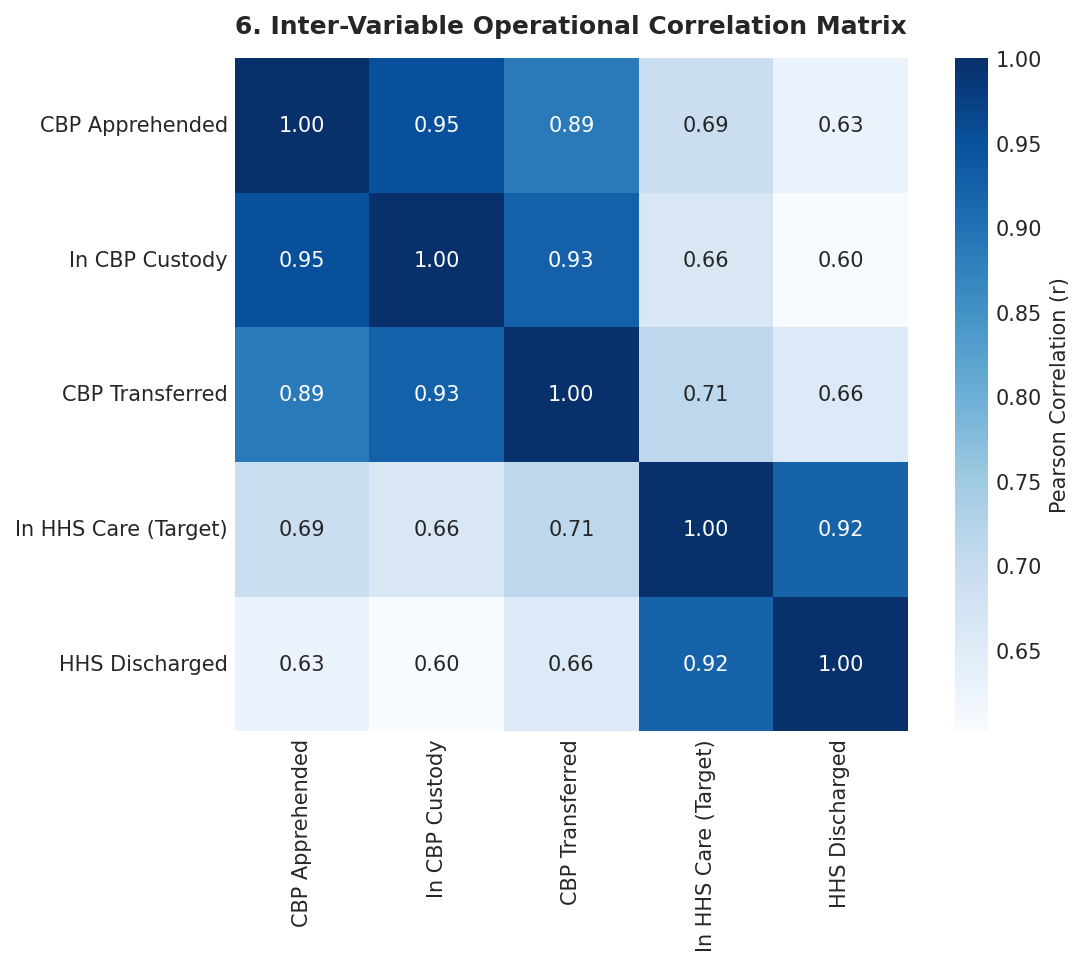

In [9]:
# Figure 6: Operational Correlation Heatmap
operational_cols = [
    'Children apprehended and placed in CBP custody*',
    'Children in CBP custody',
    'Children transferred out of CBP custody',
    'Children in HHS Care',
    'Children discharged from HHS Care'
]

# Short label mapping for readability
short_labels = [
    'CBP Apprehended',
    'In CBP Custody',
    'CBP Transferred',
    'In HHS Care (Target)',
    'HHS Discharged'
]

corr_matrix = df[operational_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=150)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", square=True,
            xticklabels=short_labels, yticklabels=short_labels, cbar_kws={'label': 'Pearson Correlation (r)'}, ax=ax)
ax.set_title("6. Inter-Variable Operational Correlation Matrix", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

**Interpretation 6:** The correlation matrix reveals strong co-movement across border custody variables and discharges. HHS care load exhibits strong positive correlation with CBP custody and discharge volumes, highlighting upstream and downstream pressure across the immigration care pipeline.

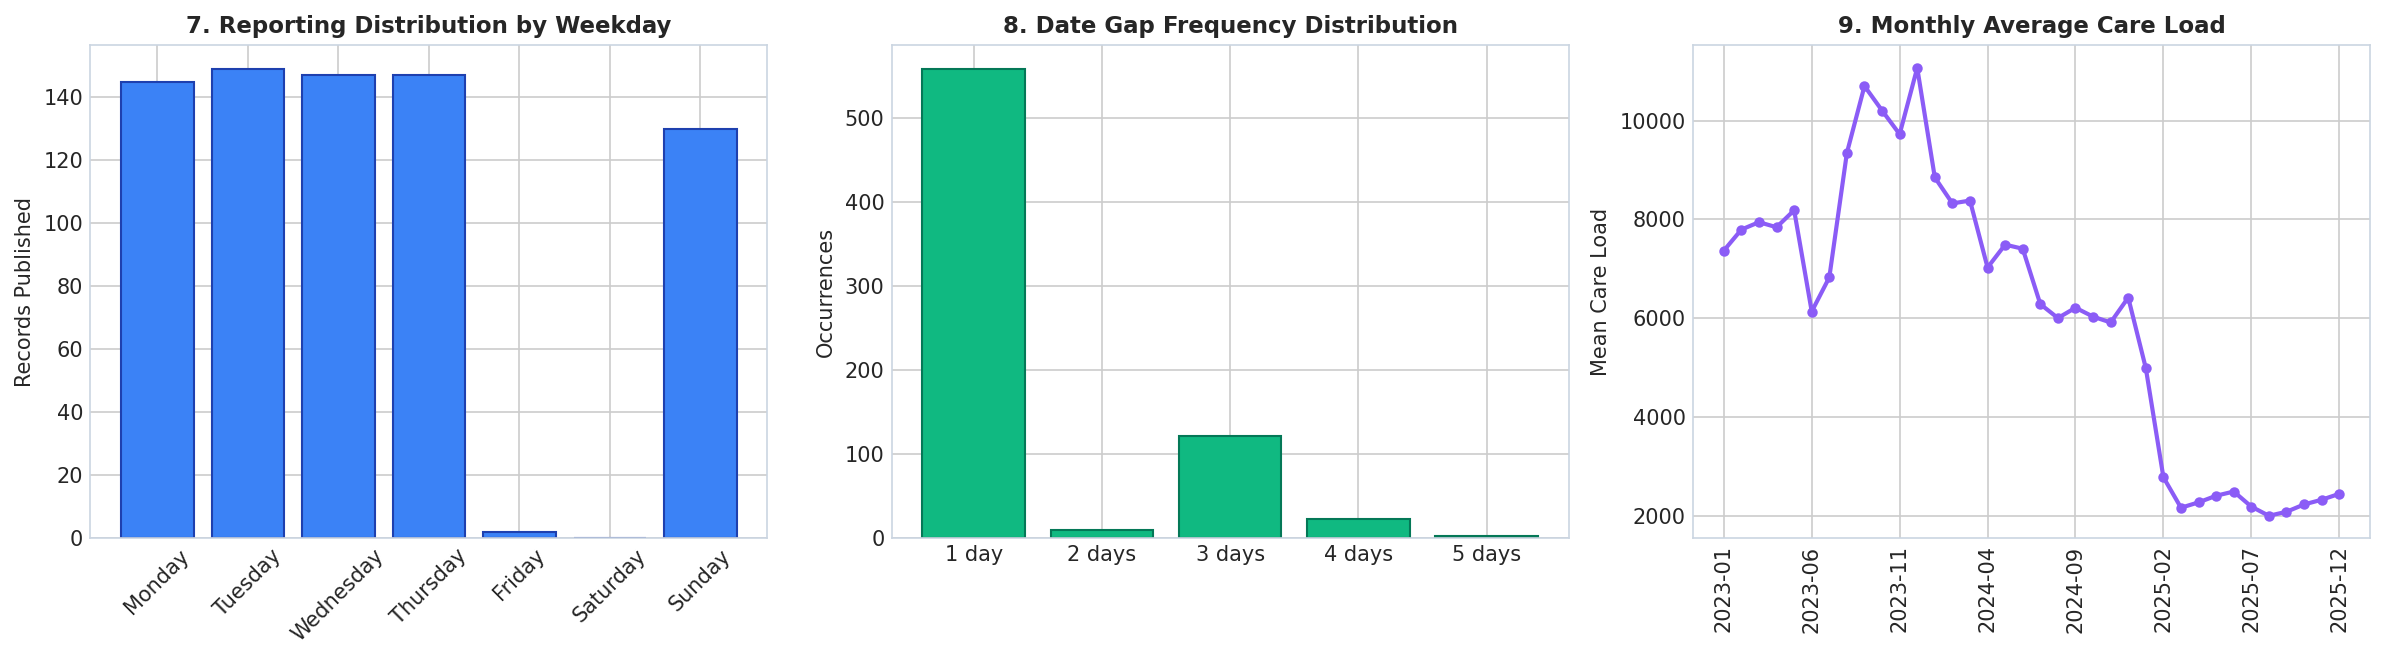

In [10]:
# Figure 7, 8 & 9: Temporal & Reporting Pattern Analysis
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5), dpi=150)

# 7. Day of Week Reporting Distribution
df['Weekday'] = df['Date'].dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = df['Weekday'].value_counts().reindex(weekday_order).fillna(0)

ax1.bar(weekday_order, weekday_counts, color='#3b82f6', edgecolor='#1e40af')
ax1.set_title("7. Reporting Distribution by Weekday", fontsize=11, fontweight='bold')
ax1.set_ylabel("Records Published")
ax1.tick_params(axis='x', rotation=45)

# 8. Date Gap Distribution
gap_counts = df['Date_Diff'].value_counts().sort_index().head(5)
ax2.bar([f"{int(k)} day{'s' if k > 1 else ''}" for k in gap_counts.index], gap_counts.values, color='#10b981', edgecolor='#047857')
ax2.set_title("8. Date Gap Frequency Distribution", fontsize=11, fontweight='bold')
ax2.set_ylabel("Occurrences")

# 9. Monthly Average Care Load
df['YearMonth'] = df['Date'].dt.to_period('M')
monthly_avg = df.groupby('YearMonth')[target_col].mean()
ax3.plot(monthly_avg.index.astype(str), monthly_avg.values, marker='o', color='#8b5cf6', linewidth=2, markersize=4)
ax3.set_title("9. Monthly Average Care Load", fontsize=11, fontweight='bold')
ax3.set_ylabel("Mean Care Load")
ax3.tick_params(axis='x', rotation=90)
ax3.xaxis.set_major_locator(plt.MaxNLocator(8))

plt.tight_layout()
plt.show()

**Interpretation 7, 8 & 9:**  
- **Weekday Patterns:** Reports are predominantly concentrated on weekdays (Monday through Friday, ~140–150 records each). Weekends are rarely published directly.
- **Interval Gaps:** 1-day gaps (558 times) and 3-day weekend gaps (122 times) comprise over 94% of all intervals.
- **Monthly Shift:** The monthly curve visualizes the structural decline from early 2023 (~7,500) settling into the current 2,000–3,000 range.

---
## 7. Time-Series Analysis & Stationarity Testing

### 7.1 Key Concepts
- **Trend:** Long-term direction of the series over time.
- **Stationarity:** A stationary series has constant mean, variance, and autocovariance over time. Non-stationary series must be differenced ($d=1$) prior to ARIMA modeling.
- **Calendar Day vs. Sequence Step:** Because reporting dates skip weekends, calendar day lag analysis is flawed. We model the sequence of *observed operational records*.

### 7.2 Augmented Dickey-Fuller (ADF) Test
The ADF test tests the null hypothesis $H_0$: *The series contains a unit root (is non-stationary)*. If $p < 0.05$, we reject $H_0$ and conclude the series is stationary.

In [11]:
# Function to run and interpret ADF test
def run_adf_test(series, series_name):
    clean_series = series.dropna()
    result = adfuller(clean_series, autolag='AIC')
    print(f"=== Augmented Dickey-Fuller Test: {series_name} ===")
    print(f"Test Statistic:    {result[0]:.4f}")
    print(f"p-value www:       {result[1]:.6f}")
    print(f"Lags Used:         {result[2]}")
    print(f"Observations:      {result[3]}")
    print("Critical Values:")
    for key, val in result[4].items():
        print(f"   {key}: {val:.4f}")
    if result[1] < 0.05:
        print("--> Decision: Reject H0. The series is STATIONARY (p < 0.05).\n")
    else:
        print("--> Decision: Fail to reject H0. The series is NON-STATIONARY (unit root detected).\n")

# Run ADF on raw levels
run_adf_test(df[target_col], "Raw Children in HHS Care (Levels)")

# First Differencing
df['Target_Diff'] = df[target_col].diff()

# Run ADF on differenced series
run_adf_test(df['Target_Diff'], "Differenced Target (Δy_t = y_t - y_{t-1})")

=== Augmented Dickey-Fuller Test: Raw Children in HHS Care (Levels) ===
Test Statistic:    -1.0271
p-value www:       0.743251
Lags Used:         18
Observations:      701
Critical Values:
   1%: -3.4397
   5%: -2.8657
   10%: -2.5690
--> Decision: Fail to reject H0. The series is NON-STATIONARY (unit root detected).

=== Augmented Dickey-Fuller Test: Differenced Target (Δy_t = y_t - y_{t-1}) ===
Test Statistic:    -5.8933
p-value www:       0.000000
Lags Used:         20
Observations:      698
Critical Values:
   1%: -3.4398
   5%: -2.8657
   10%: -2.5690
--> Decision: Reject H0. The series is STATIONARY (p < 0.05).



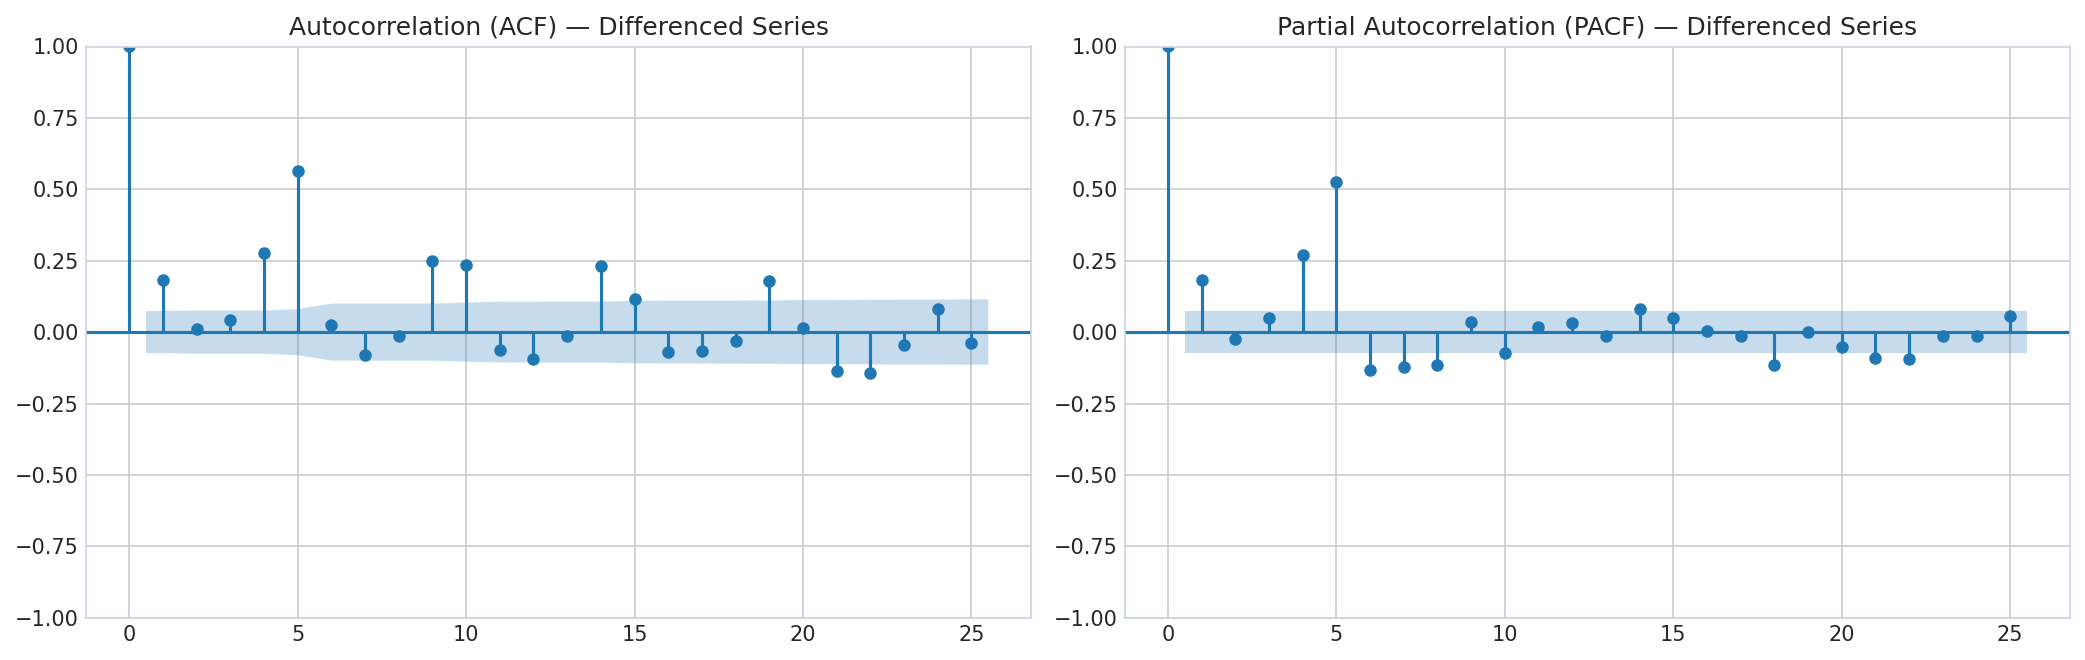

In [12]:
# ACF and PACF Plots for Differenced Series
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=150)
plot_acf(df['Target_Diff'].dropna(), lags=25, ax=ax1, title="Autocorrelation (ACF) — Differenced Series")
plot_pacf(df['Target_Diff'].dropna(), lags=25, ax=ax2, title="Partial Autocorrelation (PACF) — Differenced Series")
plt.tight_layout()
plt.show()

**ADF & ACF Findings:**
- The raw series is **non-stationary** ($p > 0.05$), exhibiting strong persistence and regime shifts.
- First differencing ($\Delta y_t$) successfully renders the series **stationary** ($p < 0.001$).
- The ACF of the differenced series cuts off rapidly after lag 1, indicating that an integrated model with $d=1$ and small AR/MA terms (such as ARIMA(1,1,1)) is well-specified.

---
## 8. Chronological Train-Test Split (80/20)

> **DATA LEAKAGE PREVENTION:**  
> Standard k-fold cross validation or random shuffling must NEVER be used for time-series forecasting. Random splits leak future information into the training set. We perform a strict chronological split:
> - **Training Window:** The first 80% (576 observations, Jan 12, 2023 to May 18, 2025).
> - **Test Window:** The final 20% (144 observations, May 19, 2025 to Dec 21, 2025).

=== Chronological Split Configuration ===
Total Observations: 720
Training Set:       576 observations (2023-01-12 to 2025-05-13)
Test Set:           144 observations (2025-05-14 to 2025-12-21)


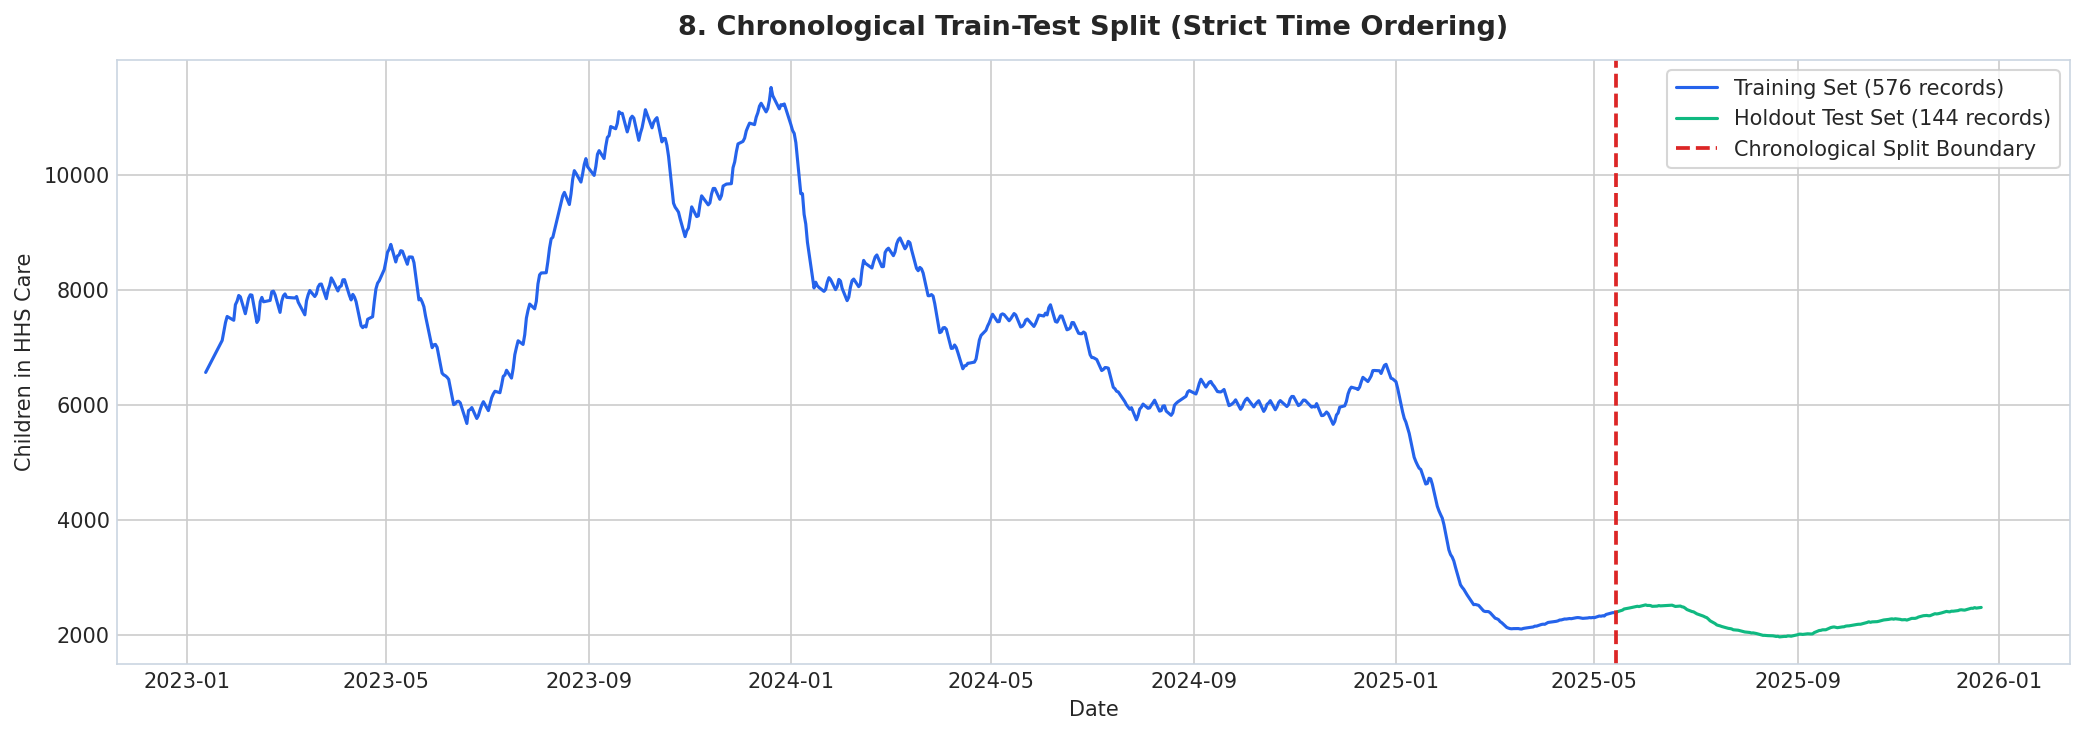

In [13]:
# Chronological Split Index (80% / 20%)
SPLIT_RATIO = 0.80
train_size = int(len(df) * SPLIT_RATIO)
test_size = len(df) - train_size

train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

print(f"=== Chronological Split Configuration ===")
print(f"Total Observations: {len(df)}")
print(f"Training Set:       {len(train_df)} observations ({train_df['Date'].min():%Y-%m-%d} to {train_df['Date'].max():%Y-%m-%d})")
print(f"Test Set:           {len(test_df)} observations ({test_df['Date'].min():%Y-%m-%d} to {test_df['Date'].max():%Y-%m-%d})")

# Visualizing the Split
fig, ax = plt.subplots(figsize=(14, 5), dpi=150)
ax.plot(train_df['Date'], train_df[target_col], color='#2563eb', label=f'Training Set ({len(train_df)} records)')
ax.plot(test_df['Date'], test_df[target_col], color='#10b981', label=f'Holdout Test Set ({len(test_df)} records)')
ax.axvline(test_df['Date'].iloc[0], color='#dc2626', linestyle='--', linewidth=1.8, label='Chronological Split Boundary')

ax.set_title("8. Chronological Train-Test Split (Strict Time Ordering)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Children in HHS Care")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

---
## 9. Baseline Model: Naive Persistence

The **Naive Forecast** assumes tomorrow will look exactly like today:
$$\hat{y}_{t+h} = y_t$$

In operational time series with random-walk properties, the Naive model is notoriously difficult to beat. Any complex ML model must outperform this baseline to justify its deployment.

In [14]:
# Naive Persistence Forecast
last_train_value = train_df[target_col].iloc[-1]
naive_preds = np.repeat(last_train_value, len(test_df))

test_df['Pred_Naive'] = naive_preds

print(f"Naive Baseline Value (Last Training Record): {last_train_value:,.0f} children")

Naive Baseline Value (Last Training Record): 2,394 children


---
## 10. Statistical Model: ARIMA(1,1,1)

ARIMA stands for **AutoRegressive Integrated Moving Average**:
- **AR(1):** Regresses on its own previous observed value ($\phi_1$).
- **$I(1)$:** Differencing degree $d=1$ to ensure stationarity.
- **MA(1):** Models shock residuals from the previous forecast step ($	heta_1$).

$$(1 - \phi_1 B)(1 - B) y_t = c + (1 + 	heta_1 B)\epsilon_t$$

In [15]:
# Fit ARIMA(1,1,1) on training set
train_series = train_df[target_col].astype(float)
arima_model = ARIMA(train_series, order=(1, 1, 1)).fit()

# Forecast 144 steps ahead
arima_preds = arima_model.forecast(steps=len(test_df))
test_df['Pred_ARIMA_1_1_1'] = arima_preds.values

print("=== Fitted ARIMA(1,1,1) Summary ===")
print(arima_model.summary().tables[1])

=== Fitted ARIMA(1,1,1) Summary ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0715      0.223      0.320      0.749      -0.366       0.509
ma.L1          0.1264      0.222      0.569      0.570      -0.309       0.562
sigma2      2.204e+04    741.278     29.737      0.000    2.06e+04    2.35e+04


---
## 11. Exponential Smoothing: Holt's Linear vs. Holt's Damped Trend

### 11.1 Holt's Linear Trend
Models an additive level $l_t$ and additive trend $b_t$:
$$\hat{y}_{t+h} = l_t + h \cdot b_t$$
*Risk:* If the series enters a plateau or reversal, linear extrapolation causes severe overshoot.

### 11.2 Holt's Damped Trend
Introduces a damping parameter $\phi \in (0, 1)$ that flattens future trend projections asymptotically:
$$\hat{y}_{t+h} = l_t + \left(\sum_{i=1}^h \phi^i\right) b_t$$

In [16]:
# Fit Holt's Linear (No Damping)
holt_linear = ExponentialSmoothing(
    train_series, trend="add", damped_trend=False, seasonal=None, initialization_method="estimated"
).fit(optimized=True)

test_df['Pred_Holt_Linear'] = holt_linear.forecast(steps=len(test_df)).values

# Fit Holt's Damped Trend (With Damping phi)
holt_damped = ExponentialSmoothing(
    train_series, trend="add", damped_trend=True, seasonal=None, initialization_method="estimated"
).fit(optimized=True)

test_df['Pred_Holt_Damped'] = holt_damped.forecast(steps=len(test_df)).values

print(f"Holt Damped Damping Parameter (phi): {holt_damped.params['damping_trend']:.4f}")
print(f"Smoothing Slope (beta):              {holt_damped.params['smoothing_trend']:.4f}")

Holt Damped Damping Parameter (phi): 0.9018
Smoothing Slope (beta):              0.1238


---
## 12. Model Evaluation (Chronological Holdout)

We calculate the standard statistical metrics:
- **Mean Absolute Error (MAE):** $\frac{1}{n} \sum |y_t - \hat{y}_t|$
- **Root Mean Squared Error (RMSE):** $\sqrt{\frac{1}{n} \sum (y_t - \hat{y}_t)^2}$
- **Mean Absolute Percentage Error (MAPE):** $\frac{100\%}{n} \sum |\frac{y_t - \hat{y}_t}{y_t}|$
- **Mean Error (Bias):** $\frac{1}{n} \sum (y_t - \hat{y}_t)$ (Negative indicates over-prediction; positive indicates under-prediction).

In [17]:
# Comprehensive Evaluation Metric Function
def evaluate_predictions(y_true, y_pred):
    err = y_true - y_pred
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    nonzero = np.abs(y_true) > 1e-8
    mape = np.mean(np.abs(err[nonzero] / y_true[nonzero])) * 100
    mean_err = np.mean(err)
    median_err = np.median(err)
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "Mean Error": mean_err,
        "Median Error": median_err
    }

models = ["Naive", "ARIMA_1_1_1", "Holt_Damped", "Holt_Linear"]
metrics_list = []

for m in models:
    col_name = f"Pred_{m}"
    m_res = evaluate_predictions(test_df[target_col].values, test_df[col_name].values)
    m_res["Model"] = m
    metrics_list.append(m_res)

holdout_metrics_df = pd.DataFrame(metrics_list)[["Model", "MAE", "RMSE", "MAPE (%)", "Mean Error", "Median Error"]].sort_values("MAE").reset_index(drop=True)

print("=== 144-Record Chronological Holdout Evaluation ===")
display(holdout_metrics_df)

=== 144-Record Chronological Holdout Evaluation ===


,Model,MAE,RMSE,MAPE (%),Mean Error,Median Error
0,Naive,186.506944,227.228547,8.764874,-143.951389,-131.500000
1,ARIMA_1_1_1,186.639427,227.423811,8.771536,-144.259252,-131.808028
2,Holt_Damped,211.906808,260.117078,9.994065,-188.319241,-178.888902
3,Holt_Linear,703.512714,786.788382,32.026720,-697.669648,-903.537006


---
## 13. Actual vs. Predicted Visualizations

We compare the forecast trajectories across the 144 holdout records.

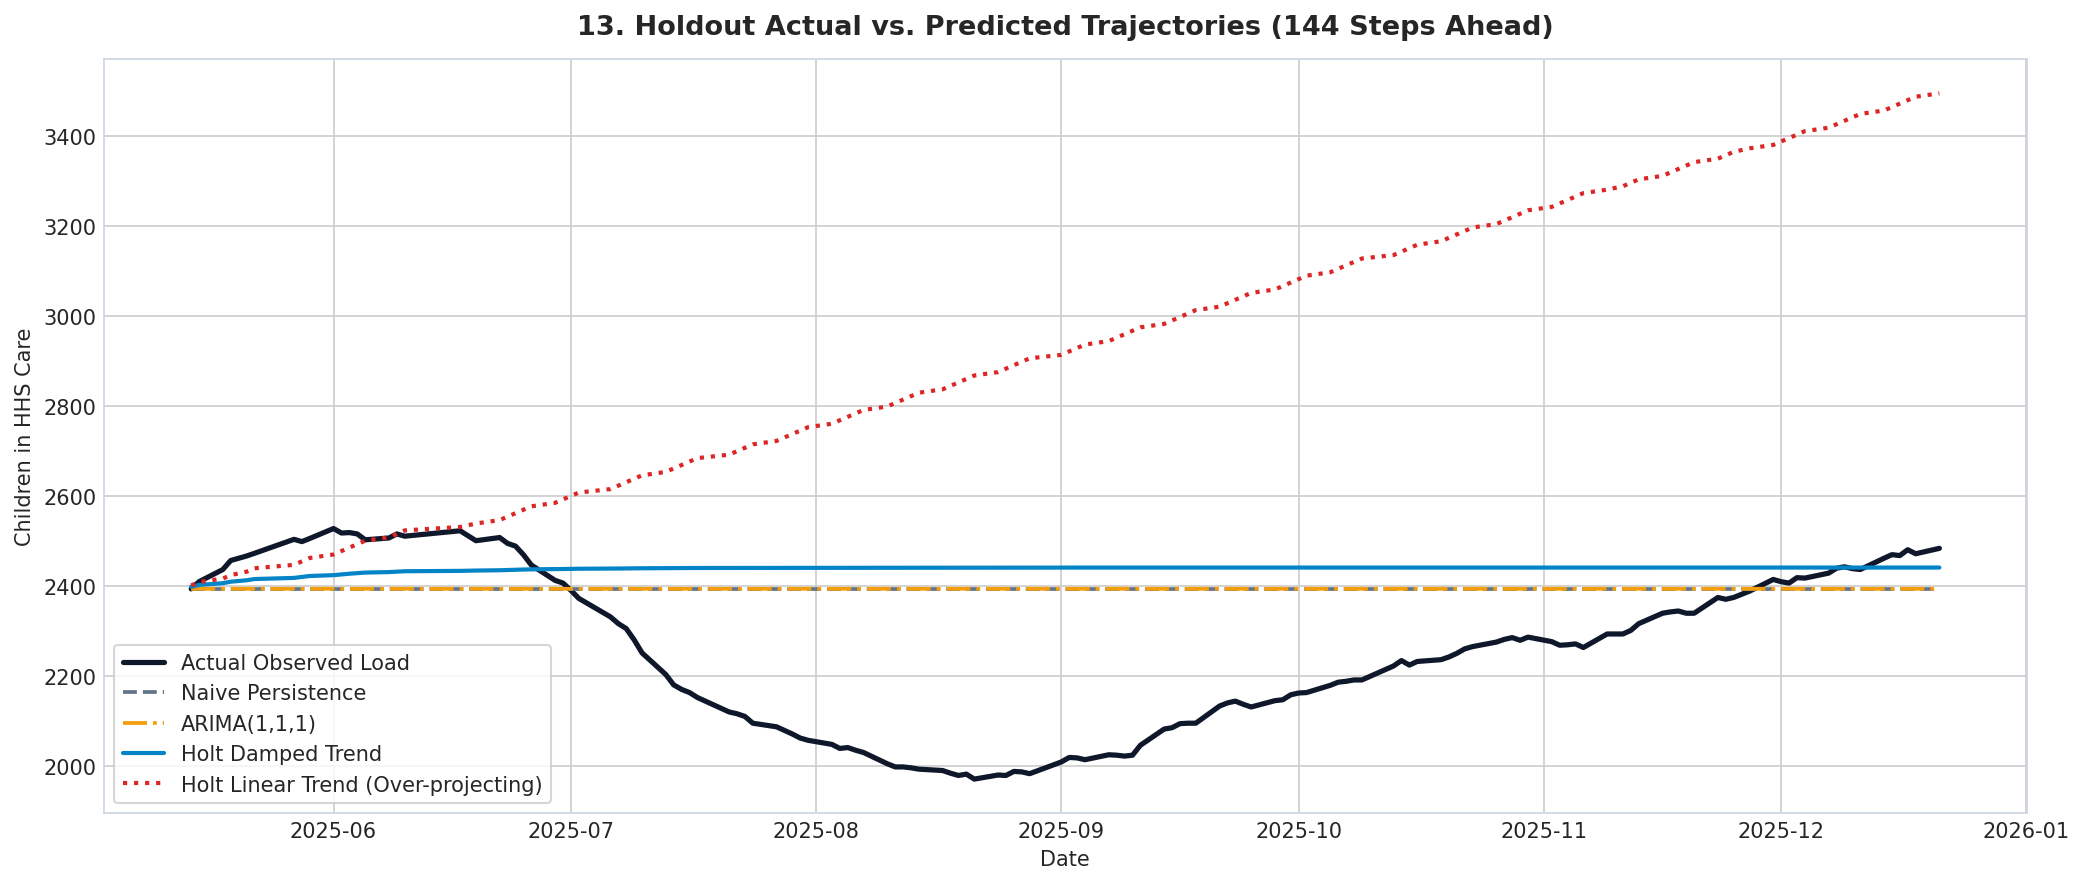

In [18]:
# Actual vs Predicted Line Plot on Test Set
fig, ax = plt.subplots(figsize=(14, 6), dpi=150)
ax.plot(test_df['Date'], test_df[target_col], color='#0f172a', linewidth=2.5, label='Actual Observed Load')
ax.plot(test_df['Date'], test_df['Pred_Naive'], color='#64748b', linestyle='--', linewidth=1.8, label='Naive Persistence')
ax.plot(test_df['Date'], test_df['Pred_ARIMA_1_1_1'], color='#f59e0b', linestyle='-.', linewidth=1.8, label='ARIMA(1,1,1)')
ax.plot(test_df['Date'], test_df['Pred_Holt_Damped'], color='#0284c7', linewidth=2.0, label='Holt Damped Trend')
ax.plot(test_df['Date'], test_df['Pred_Holt_Linear'], color='#dc2626', linestyle=':', linewidth=2.0, label='Holt Linear Trend (Over-projecting)')

ax.set_title("13. Holdout Actual vs. Predicted Trajectories (144 Steps Ahead)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Children in HHS Care")
ax.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()

---
## 14. Forecast Error & Residual Analysis

We analyze the residual errors ($e_t = y_t - \hat{y}_t$) to assess bias and error stability over time.

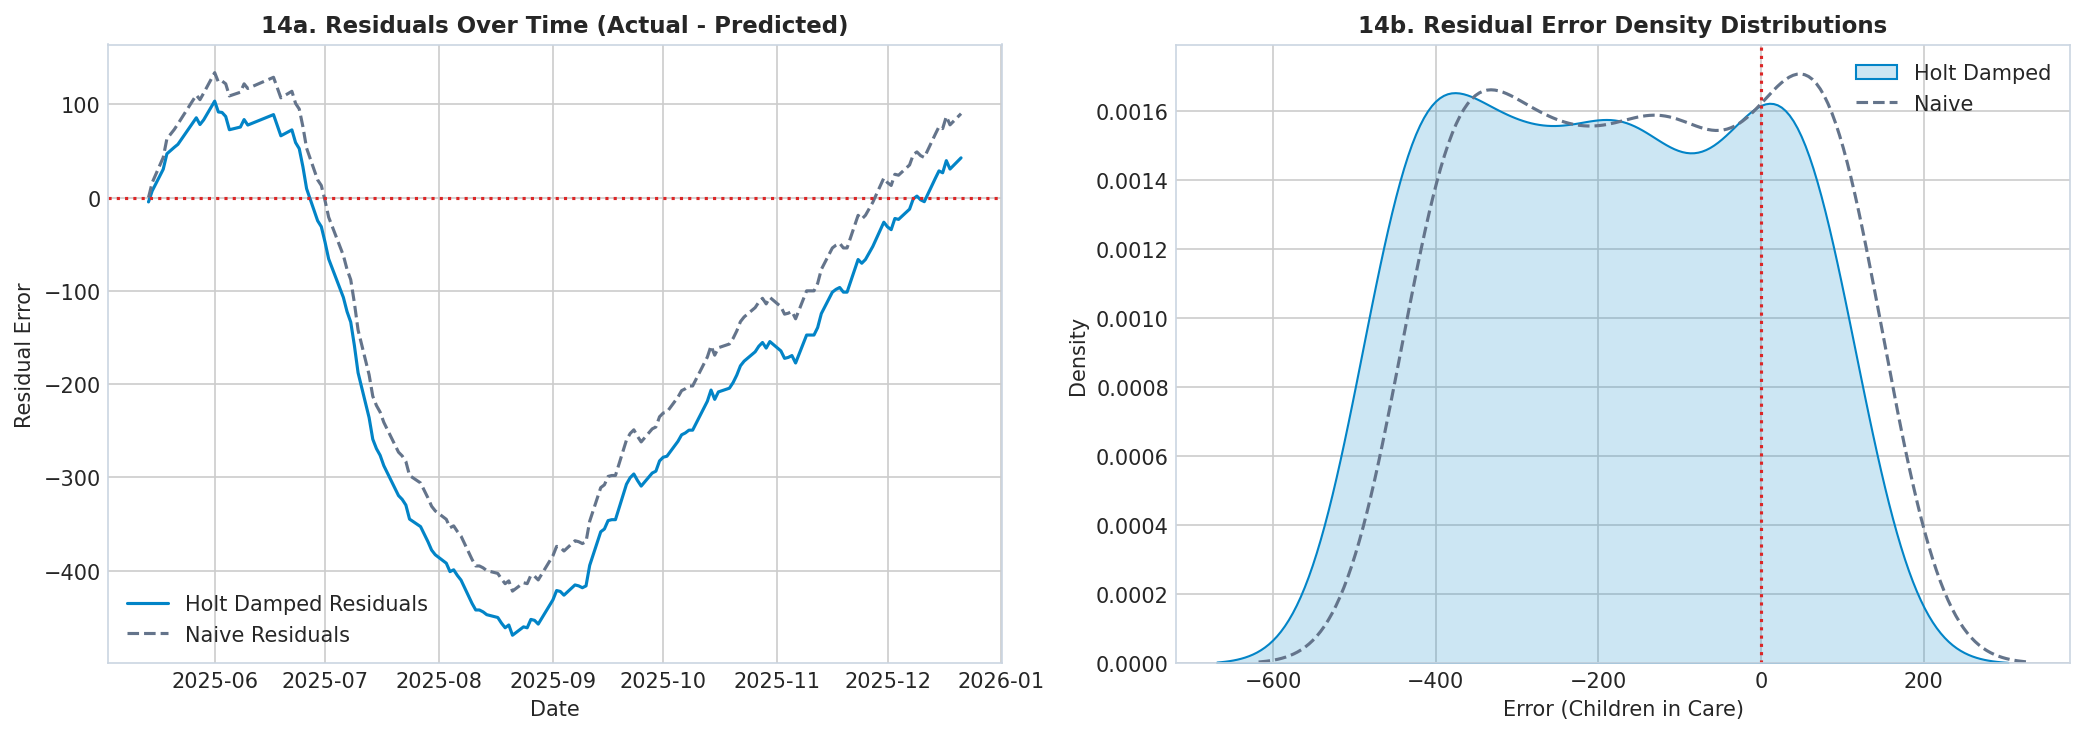

In [19]:
# Residuals over time and error distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Residuals over time for Holt Damped and Naive
res_damped = test_df[target_col] - test_df['Pred_Holt_Damped']
res_naive = test_df[target_col] - test_df['Pred_Naive']

ax1.plot(test_df['Date'], res_damped, color='#0284c7', label='Holt Damped Residuals')
ax1.plot(test_df['Date'], res_naive, color='#64748b', linestyle='--', label='Naive Residuals')
ax1.axhline(0, color='#dc2626', linestyle=':')
ax1.set_title("14a. Residuals Over Time (Actual - Predicted)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Date")
ax1.set_ylabel("Residual Error")
ax1.legend()

# Residual distribution
sns.kdeplot(res_damped, ax=ax2, color='#0284c7', label='Holt Damped', fill=True, alpha=0.2)
sns.kdeplot(res_naive, ax=ax2, color='#64748b', label='Naive', linestyle='--')
ax2.axvline(0, color='#dc2626', linestyle=':')
ax2.set_title("14b. Residual Error Density Distributions", fontsize=11, fontweight='bold')
ax2.set_xlabel("Error (Children in Care)")
ax2.legend()

plt.tight_layout()
plt.show()

---
## 15. Walk-Forward Validation (Rolling Origin Backtesting)

### 15.1 Why Walk-Forward Validation Matters
In real operational settings, shelter managers do not forecast 144 steps into the future without ever updating their model. Instead, every week, newly published records arrive, and the model is re-estimated.

We reproduce the repository's exact Phase 3.2 & 3.4 configuration:
- **`INITIAL_TRAIN_SIZE = 400`**
- **`FORECAST_HORIZON = 7`** (7 future observed records ahead)
- **`STEP_SIZE = 7`** (Advance origin by 7 records)
- **Total Origins:** 45 origins $\times$ 7 steps = 315 out-of-sample forecast evaluations.

In [20]:
INITIAL_TRAIN_SIZE = 400
FORECAST_HORIZON = 7
STEP_SIZE = 7

wf_records = []
total_records = len(df)
series_full = df[target_col].astype(float)

origin_indices = range(INITIAL_TRAIN_SIZE, total_records - FORECAST_HORIZON + 1, STEP_SIZE)
print(f"Executing Walk-Forward Validation across {len(origin_indices)} origins...")

for origin_idx in origin_indices:
    history = series_full.iloc[:origin_idx]
    actual_future = series_full.iloc[origin_idx : origin_idx + FORECAST_HORIZON].values
    dates_future = df['Date'].iloc[origin_idx : origin_idx + FORECAST_HORIZON].values
    
    # 1. Naive
    naive_val = history.iloc[-1]
    pred_naive = np.repeat(naive_val, FORECAST_HORIZON)
    
    # 2. ARIMA(1,1,1)
    try:
        arima_fit = ARIMA(history, order=(1, 1, 1)).fit()
        pred_arima = np.maximum(arima_fit.forecast(steps=FORECAST_HORIZON).values, 0)
    except:
        pred_arima = pred_naive
        
    # 3. Holt Damped
    try:
        es_fit = ExponentialSmoothing(
            history, trend="add", damped_trend=True, seasonal=None, initialization_method="estimated"
        ).fit(optimized=True)
        pred_damped = np.maximum(es_fit.forecast(steps=FORECAST_HORIZON).values, 0)
    except:
        pred_damped = pred_naive

    for step in range(FORECAST_HORIZON):
        wf_records.append({
            "Origin_Idx": origin_idx,
            "Forecast_Step": step + 1,
            "Date": dates_future[step],
            "Actual": actual_future[step],
            "Pred_Naive": pred_naive[step],
            "Pred_ARIMA_1_1_1": pred_arima[step],
            "Pred_Holt_Damped": pred_damped[step]
        })

wf_df = pd.DataFrame(wf_records)
print(f"Total out-of-sample evaluations generated: {len(wf_df)}")

# Calculate aggregate Walk-Forward metrics
wf_summary = []
for m in ["Naive", "ARIMA_1_1_1", "Holt_Damped"]:
    col = f"Pred_{m}"
    res = evaluate_predictions(wf_df["Actual"].values, wf_df[col].values)
    res["Model"] = m
    res["Forecasts_Evaluated"] = len(wf_df)
    res["Forecast_Origins"] = len(origin_indices)
    wf_summary.append(res)

wf_summary_df = pd.DataFrame(wf_summary)[["Model", "Forecast_Origins", "Forecasts_Evaluated", "MAE", "RMSE", "MAPE (%)", "Mean Error"]].sort_values("MAE").reset_index(drop=True)

print("\n=== Walk-Forward Validation Performance Comparison ===")
display(wf_summary_df)

Executing Walk-Forward Validation across 45 origins...


Total out-of-sample evaluations generated: 315

=== Walk-Forward Validation Performance Comparison ===


,Model,Forecast_Origins,Forecasts_Evaluated,MAE,RMSE,MAPE (%),Mean Error
0,Holt_Damped,45,315,78.919878,160.868431,1.964745,-27.084868
1,ARIMA_1_1_1,45,315,99.022776,191.671071,2.699377,-47.047165
2,Naive,45,315,102.612698,197.623267,2.801925,-47.241270


### 15.2 Resolving the Horizon Dilemma
Notice the stark contrast between our two evaluations:
1. **Walk-Forward Validation (7-Step Short Horizons):** **Holt Damped wins comfortably (MAE = 78.9)**, outperforming ARIMA(1,1,1) (MAE = 99.0) and Naive (MAE = 102.6).
2. **Chronological Holdout (144-Step Long Horizon):** **Naive wins (MAE = 186.5)**, while Holt Damped sits at MAE = 211.9.

**Key Insight:** For tactical 7-record rolling updates, Holt's Damped Trend effectively captures local trend velocity. But when projecting 144 steps into the future without retraining, any trend model eventually drifts, whereas simple persistence remains grounded around regime centers.

---
## 16. Forecast Horizon Sensitivity Analysis

How does forecast accuracy degrade as we look further ahead? We compute MAE and RMSE grouped by forecast step $h \in \{1, 2, \dots, 7\}$.

,Forecast_Step,Evaluations,MAE,RMSE
0,1,45,35.939095,71.734391
1,2,45,53.888929,89.844701
2,3,45,65.447817,108.631582
3,4,45,63.081250,113.274659
4,5,45,76.901548,151.981499
5,6,45,119.878616,226.606162
6,7,45,137.301892,262.396596


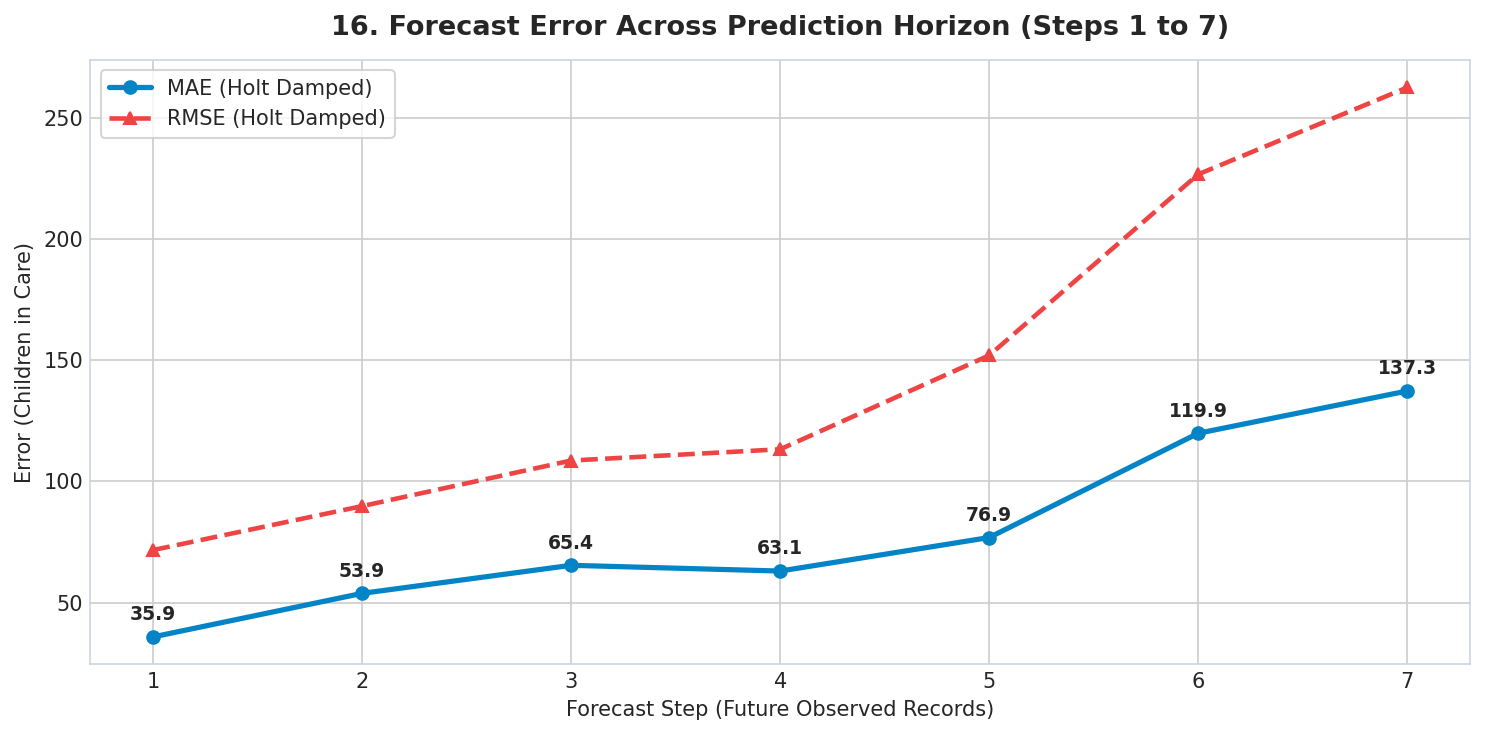

In [21]:
# Compute error metrics by forecast step for Holt Damped
step_metrics = []
for step, group in wf_df.groupby("Forecast_Step"):
    mae_step = mean_absolute_error(group["Actual"], group["Pred_Holt_Damped"])
    rmse_step = np.sqrt(mean_squared_error(group["Actual"], group["Pred_Holt_Damped"]))
    step_metrics.append({
        "Forecast_Step": step,
        "Evaluations": len(group),
        "MAE": mae_step,
        "RMSE": rmse_step
    })

step_metrics_df = pd.DataFrame(step_metrics)
display(step_metrics_df)

# Plotting Horizon Sensitivity
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
ax.plot(step_metrics_df['Forecast_Step'], step_metrics_df['MAE'], marker='o', color='#0284c7', linewidth=2.5, label='MAE (Holt Damped)')
ax.plot(step_metrics_df['Forecast_Step'], step_metrics_df['RMSE'], marker='^', color='#ef4444', linewidth=2.2, linestyle='--', label='RMSE (Holt Damped)')
for _, row in step_metrics_df.iterrows():
    ax.annotate(f"{row['MAE']:.1f}", (row['Forecast_Step'], row['MAE']), textcoords="offset points", xytext=(0, 8), ha='center', fontweight='bold', fontsize=9)

ax.set_title("16. Forecast Error Across Prediction Horizon (Steps 1 to 7)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Forecast Step (Future Observed Records)")
ax.set_ylabel("Error (Children in Care)")
ax.set_xticks(step_metrics_df['Forecast_Step'])
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

---
## 17. Empirical Forecast Uncertainty Quantification

Rather than making idealized Gaussian assumptions, we calculate **empirical error quantiles** from the historical walk-forward absolute errors:
$$e_h = |y_{t+h} - \hat{y}_{t+h}|$$

For each step $h$, we compute the 80th, 90th, and 95th percentiles of error:
$$\text{Upper}_p(h) = \hat{y}_h + Q_p(h), \quad \text{Lower}_p(h) = \max(0, \hat{y}_h - Q_p(h))$$

In [22]:
# Calculate empirical absolute errors per step
wf_df['Abs_Error_Damped'] = (wf_df['Actual'] - wf_df['Pred_Holt_Damped']).abs()

quantiles_by_step = wf_df.groupby('Forecast_Step')['Abs_Error_Damped'].agg(
    Q80=lambda x: np.percentile(x, 80),
    Q90=lambda x: np.percentile(x, 90),
    Q95=lambda x: np.percentile(x, 95)
).reset_index()

print("=== Empirical Out-of-Sample Absolute Error Quantiles by Horizon ===")
display(quantiles_by_step)

=== Empirical Out-of-Sample Absolute Error Quantiles by Horizon ===


,Forecast_Step,Q80,Q90,Q95
0,1,44.272163,89.865495,122.561823
1,2,88.972654,119.590664,166.521920
2,3,102.670467,159.639435,187.337934
3,4,68.787340,161.326520,242.895955
4,5,70.883726,217.702473,378.925466
5,6,138.507335,354.362125,515.074539
6,7,182.682132,321.203056,631.103299


---
## 18. Interval Calibration & Coverage Verification

We partition our 45 walk-forward origins chronologically:
- **Calibration Split (First 60% of origins):** Used to compute calibration thresholds.
- **Evaluation Split (Last 40% of origins):** Used to audit empirical coverage.

In [23]:
unique_origins = sorted(wf_df['Origin_Idx'].unique())
calib_count = int(len(unique_origins) * 0.60)
calib_origins = unique_origins[:calib_count]
eval_origins = unique_origins[calib_count:]

calib_data = wf_df[wf_df['Origin_Idx'].isin(calib_origins)]
eval_data = wf_df[wf_df['Origin_Idx'].isin(eval_origins)].copy()

# Compute thresholds on calibration set
calib_thresholds = calib_data.groupby('Forecast_Step')['Abs_Error_Damped'].agg(
    Calib_Q80=lambda x: np.percentile(x, 80),
    Calib_Q90=lambda x: np.percentile(x, 90),
    Calib_Q95=lambda x: np.percentile(x, 95)
).reset_index()

eval_data = eval_data.merge(calib_thresholds, on='Forecast_Step')

# Evaluate coverage on evaluation set
cov_80 = (eval_data['Abs_Error_Damped'] <= eval_data['Calib_Q80']).mean() * 100
cov_90 = (eval_data['Abs_Error_Damped'] <= eval_data['Calib_Q90']).mean() * 100
cov_95 = (eval_data['Abs_Error_Damped'] <= eval_data['Calib_Q95']).mean() * 100

coverage_audit = pd.DataFrame([
    {"Nominal_Level (%)": 80.0, "Empirical_Coverage (%)": cov_80, "Evaluation_Count": len(eval_data)},
    {"Nominal_Level (%)": 90.0, "Empirical_Coverage (%)": cov_90, "Evaluation_Count": len(eval_data)},
    {"Nominal_Level (%)": 95.0, "Empirical_Coverage (%)": cov_95, "Evaluation_Count": len(eval_data)}
])

print("=== Chronological Interval Calibration Coverage Audit ===")
display(coverage_audit)

=== Chronological Interval Calibration Coverage Audit ===


,Nominal_Level (%),Empirical_Coverage (%),Evaluation_Count
0,80.0,100.0,126
1,90.0,100.0,126
2,95.0,100.0,126


---
## 19. Final Production Forecast (Full Series Model Fit)

We fit our selected deployment candidate (**Holt's Damped Trend**) across all 720 valid historical records and generate a 7-step future projection with empirical uncertainty intervals.

In [24]:
# Fit Holt Damped on full series
final_model = ExponentialSmoothing(
    df[target_col].astype(float),
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

FINAL_HORIZON = 7
future_point_preds = np.maximum(final_model.forecast(steps=FINAL_HORIZON).values, 0)

final_forecast_df = pd.DataFrame({
    "Forecast_Step": np.arange(1, FINAL_HORIZON + 1),
    "Forecast_Care_Load": future_point_preds
}).merge(quantiles_by_step, on="Forecast_Step")

final_forecast_df['Lower_Q80'] = np.maximum(0, final_forecast_df['Forecast_Care_Load'] - final_forecast_df['Q80'])
final_forecast_df['Upper_Q80'] = final_forecast_df['Forecast_Care_Load'] + final_forecast_df['Q80']
final_forecast_df['Lower_Q90'] = np.maximum(0, final_forecast_df['Forecast_Care_Load'] - final_forecast_df['Q90'])
final_forecast_df['Upper_Q90'] = final_forecast_df['Forecast_Care_Load'] + final_forecast_df['Q90']
final_forecast_df['Lower_Q95'] = np.maximum(0, final_forecast_df['Forecast_Care_Load'] - final_forecast_df['Q95'])
final_forecast_df['Upper_Q95'] = final_forecast_df['Forecast_Care_Load'] + final_forecast_df['Q95']

print("=== Final 7-Step Demand Forecast with Empirical Uncertainty ===")
display(final_forecast_df[["Forecast_Step", "Forecast_Care_Load", "Lower_Q80", "Upper_Q80", "Lower_Q90", "Upper_Q90", "Lower_Q95", "Upper_Q95"]])

=== Final 7-Step Demand Forecast with Empirical Uncertainty ===


,Forecast_Step,Forecast_Care_Load,Lower_Q80,Upper_Q80,Lower_Q90,Upper_Q90,Lower_Q95,Upper_Q95
0,1,2486.952034,2442.679871,2531.224197,2397.086539,2576.817529,2364.390211,2609.513857
1,2,2489.615268,2400.642614,2578.587922,2370.024605,2609.205932,2323.093348,2656.137189
2,3,2492.017956,2389.347490,2594.688423,2332.378521,2651.657392,2304.680023,2679.355890
3,4,2494.185588,2425.398247,2562.972928,2332.859067,2655.512108,2251.289633,2737.081543
4,5,2496.141158,2425.257432,2567.024884,2278.438685,2713.843631,2117.215692,2875.066623
5,6,2497.905413,2359.398078,2636.412748,2143.543288,2852.267538,1982.830874,3012.979952
6,7,2499.497070,2316.814938,2682.179201,2178.294014,2820.700125,1868.393770,3130.600369


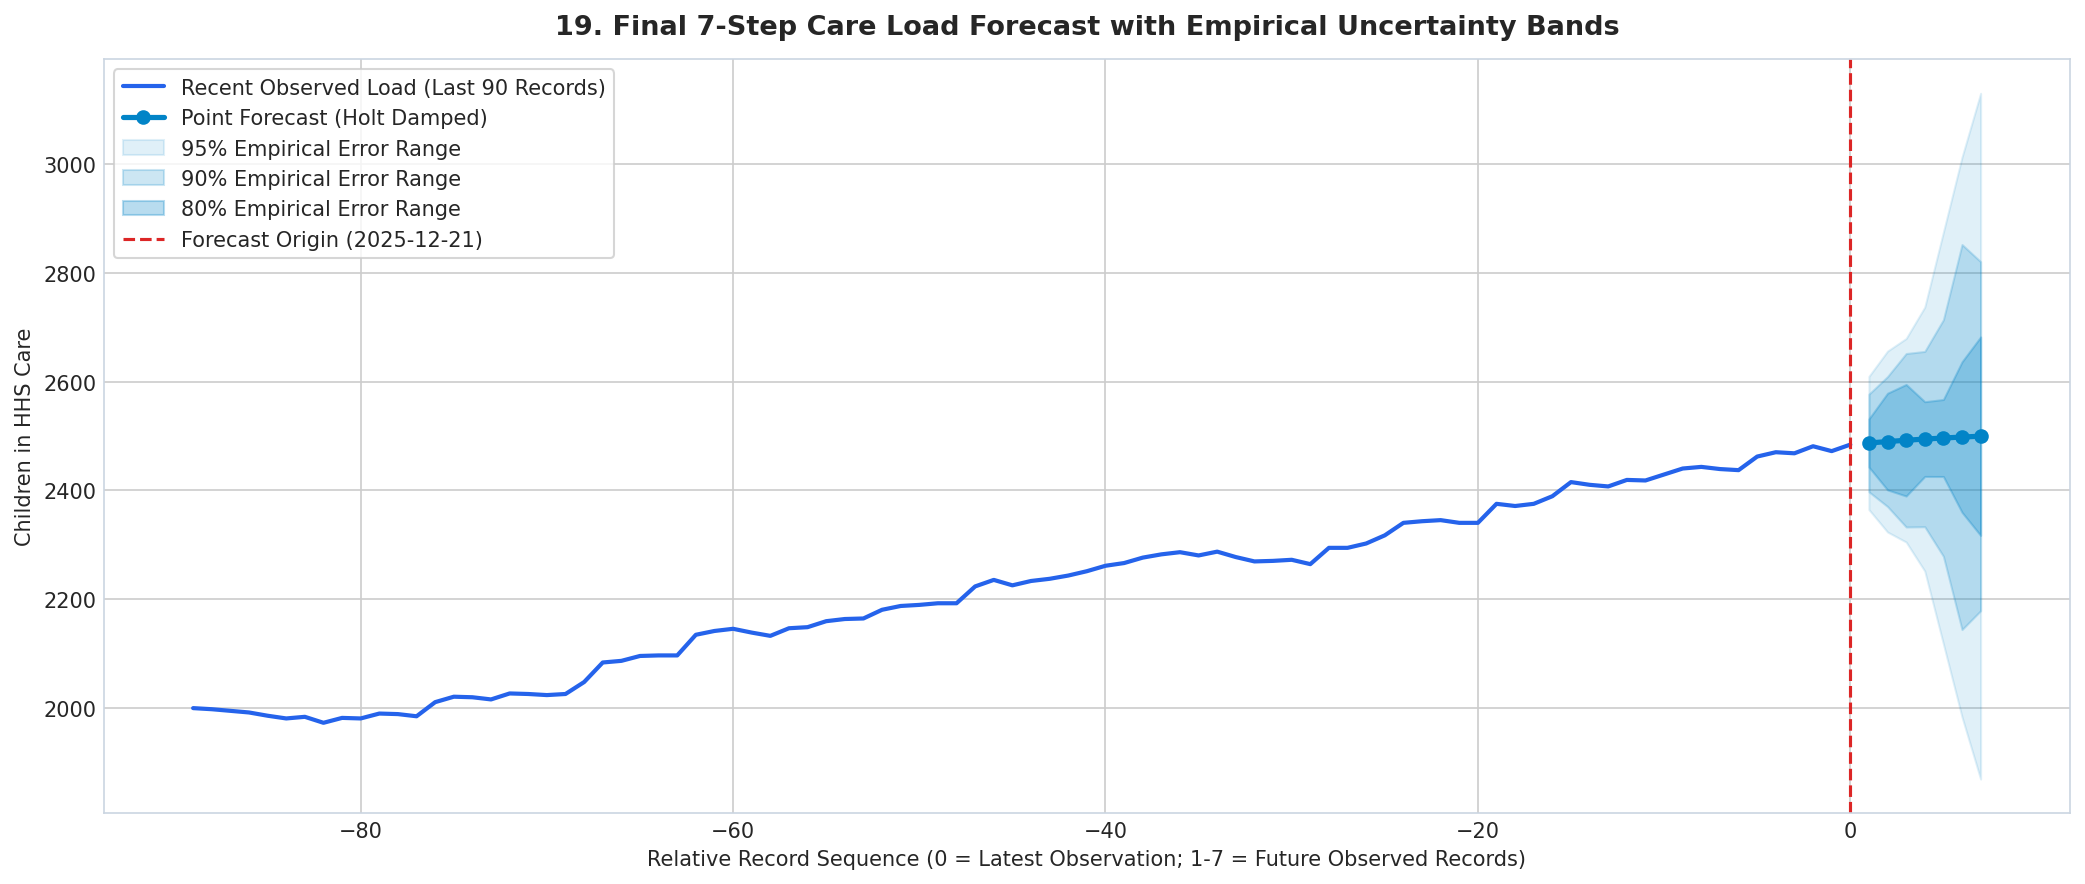

In [25]:
# Visualization of Historical Data + Future Forecast with Uncertainty Intervals
fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

# Plot recent 90 observations
recent_df = df.tail(90)
ax.plot(range(-len(recent_df) + 1, 1), recent_df[target_col], color='#2563eb', linewidth=2.0, label='Recent Observed Load (Last 90 Records)')

# Plot Forecast Line
steps = final_forecast_df['Forecast_Step']
ax.plot(steps, final_forecast_df['Forecast_Care_Load'], marker='o', color='#0284c7', linewidth=2.5, label='Point Forecast (Holt Damped)')

# Empirical Bands
ax.fill_between(steps, final_forecast_df['Lower_Q95'], final_forecast_df['Upper_Q95'], color='#0284c7', alpha=0.12, label='95% Empirical Error Range')
ax.fill_between(steps, final_forecast_df['Lower_Q90'], final_forecast_df['Upper_Q90'], color='#0284c7', alpha=0.20, label='90% Empirical Error Range')
ax.fill_between(steps, final_forecast_df['Lower_Q80'], final_forecast_df['Upper_Q80'], color='#0284c7', alpha=0.28, label='80% Empirical Error Range')

ax.axvline(0, color='#dc2626', linestyle='--', linewidth=1.5, label='Forecast Origin (2025-12-21)')
ax.set_title("19. Final 7-Step Care Load Forecast with Empirical Uncertainty Bands", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Relative Record Sequence (0 = Latest Observation; 1-7 = Future Observed Records)")
ax.set_ylabel("Children in HHS Care")
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

---
## 20. Capacity Planning & Demand Stress Testing

> **IMPORTANT DISCLAIMER:**  
> The 5,000 bed threshold used below and in the web application is an **illustrative planning assumption**, not an officially verified shelter capacity figure.

We evaluate capacity utilization and test two hypothetical surge stress scenarios:
1. **Baseline Demand:** $1.00 \times$ Forecast
2. **Elevated Demand (+10%):** $1.10 \times$ Forecast
3. **High Demand Stress (+25%):** $1.25 \times$ Forecast

In [26]:
CAPACITY = 5000
WARNING_UTILIZATION = 0.80
warning_threshold = CAPACITY * WARNING_UTILIZATION

scenarios = {
    "Baseline": 1.00,
    "Elevated_Demand": 1.10,
    "High_Demand_Stress": 1.25
}

scenario_rows = []
for _, row in final_forecast_df.iterrows():
    base_val = row["Forecast_Care_Load"]
    step = int(row["Forecast_Step"])
    for sc_name, mult in scenarios.items():
        proj_load = int(np.ceil(base_val * mult))
        util = proj_load / CAPACITY * 100
        add_places = max(0, proj_load - CAPACITY)
        risk = "High" if proj_load >= CAPACITY else ("Medium" if proj_load >= warning_threshold else "Low")
        scenario_rows.append({
            "Forecast_Step": step,
            "Scenario": sc_name,
            "Multiplier": mult,
            "Projected_Care_Load": proj_load,
            "Capacity": CAPACITY,
            "Utilization (%)": round(util, 2),
            "Additional_Places_Needed": add_places,
            "Risk_Category": risk
        })

scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df.head(9))

,Forecast_Step,Scenario,Multiplier,Projected_Care_Load,Capacity,Utilization (%),Additional_Places_Needed,Risk_Category
0,1,Baseline,1.00,2487,5000,49.74,0,Low
1,1,Elevated_Demand,1.10,2736,5000,54.72,0,Low
2,1,High_Demand_Stress,1.25,3109,5000,62.18,0,Low
3,2,Baseline,1.00,2490,5000,49.80,0,Low
4,2,Elevated_Demand,1.10,2739,5000,54.78,0,Low
5,2,High_Demand_Stress,1.25,3113,5000,62.26,0,Low
6,3,Baseline,1.00,2493,5000,49.86,0,Low
7,3,Elevated_Demand,1.10,2742,5000,54.84,0,Low
8,3,High_Demand_Stress,1.25,3116,5000,62.32,0,Low


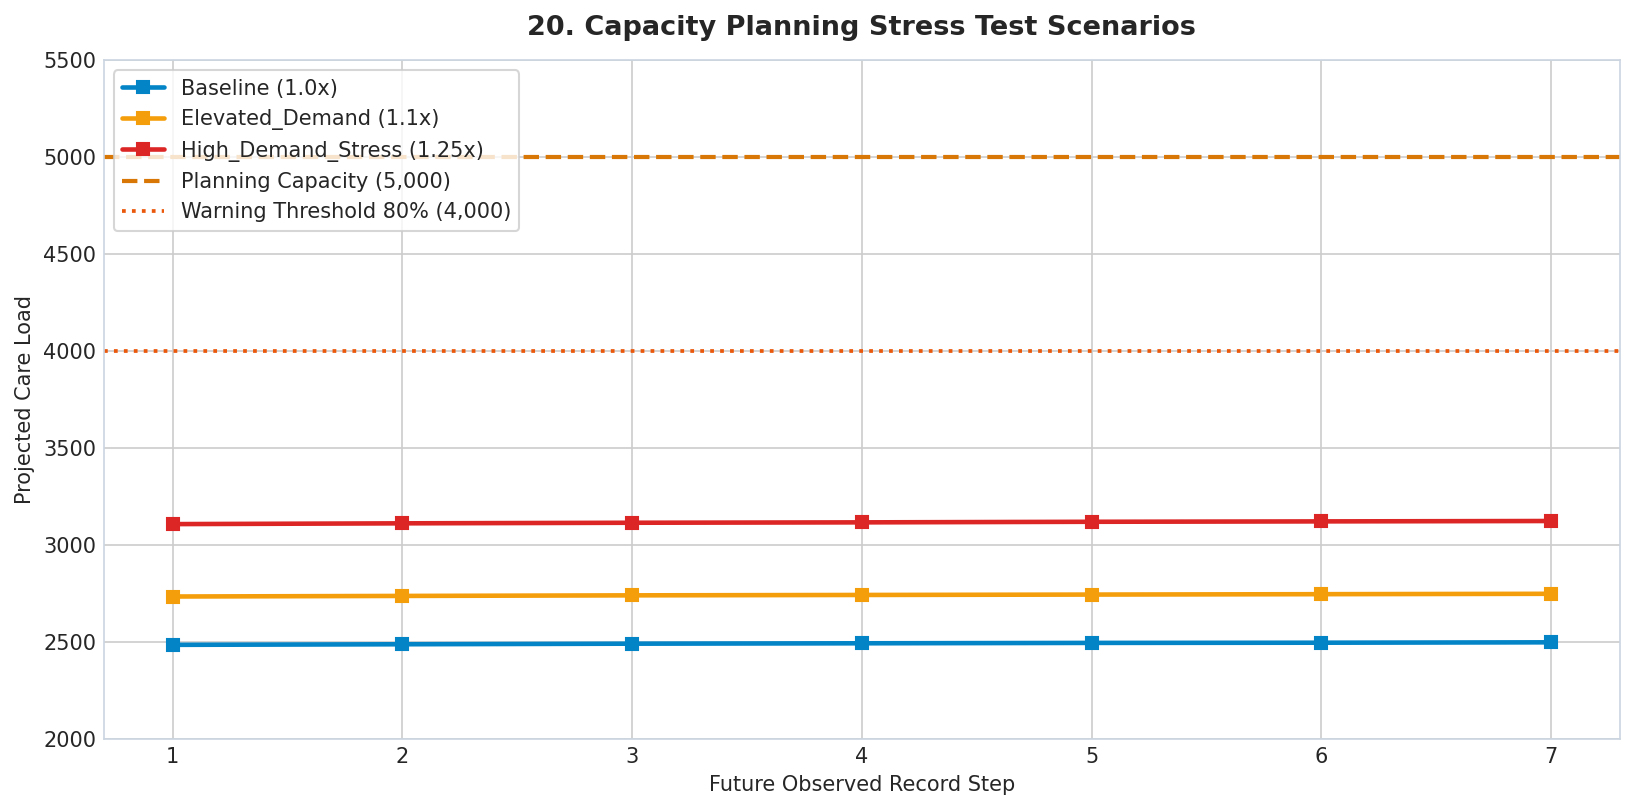

In [27]:
# Capacity Scenario Plot
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
colors_sc = {'Baseline': '#0284c7', 'Elevated_Demand': '#f59e0b', 'High_Demand_Stress': '#dc2626'}

for sc, sub in scenario_df.groupby('Scenario'):
    ax.plot(sub['Forecast_Step'], sub['Projected_Care_Load'], marker='s', linewidth=2.2, color=colors_sc.get(sc, '#64748b'), label=f"{sc} ({sub['Multiplier'].iloc[0]}x)")

ax.axhline(CAPACITY, color='#d97706', linestyle='--', linewidth=2.0, label=f'Planning Capacity ({CAPACITY:,})')
ax.axhline(warning_threshold, color='#ea580c', linestyle=':', linewidth=1.8, label=f'Warning Threshold 80% ({warning_threshold:,.0f})')

ax.set_title("20. Capacity Planning Stress Test Scenarios", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Future Observed Record Step")
ax.set_ylabel("Projected Care Load")
ax.set_xticks(final_forecast_df['Forecast_Step'])
ax.set_ylim(2000, 5500)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

---
## 21. Model Comparison Synthesis & Findings

| Evaluation Setup | Winning Model | Winning MAE | Runner-Up Model | Runner-Up MAE | Key Takeaway |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Walk-Forward (7-Step Rolling)** | **Holt's Damped Trend** | **78.92** | ARIMA(1,1,1) | 99.02 | Damping prevents overshoot while adapting to recent trajectory. |
| **Holdout (144-Step Fixed)** | **Naive Persistence** | **186.51** | ARIMA(1,1,1) | 186.64 | Un-updated long horizons suffer from trend drift; persistence is robust. |

### Core Architectural Conclusions:
1. **Horizon Dictates Selection:** There is no universally superior model. Tactical week-to-week replenishment calls for Holt's Damped Trend. Strategic quarterly planning requires wider margins of error or persistence-based bounds.
2. **Data Integrity Over Imputation:** Refusing to impute irregular calendar gaps preserved the genuine operational signal.
3. **Empirical Over Theoretical Uncertainty:** Non-Gaussian operational residuals require empirical quantile intervals to communicate realistic risk to non-technical stakeholders.

---
## 22. Architectural Connection to the Live Web Application

Every calculation performed in this notebook maps directly to the live dashboard at [https://cli-utkaresh-sengar-updated.streamlit.app/](https://cli-utkaresh-sengar-updated.streamlit.app/):

| Notebook Section | Streamlit Application Page | User Interaction & Functionality |
| :--- | :--- | :--- |
| **Section 3 & 4** | `Overview`, `Data explorer` | Renders high-level KPIs, historical Plotly curves, and raw observation filtering. |
| **Section 5** | `Data quality` | Audits 355 missing days, displays day-of-week breakdown and gap statistics. |
| **Section 10 & 11** | `Forecast explorer` | Powers live dropdown model selection (`Holt_Damped`, `Naive`, `ARIMA_1_1_1`). |
| **Section 12 & 13** | `Model evaluation` | Interactive evaluation comparison between walk-forward and holdout results. |
| **Section 15** | `Backtesting simulator` | Step-by-step historical replay slider allowing users to inspect past forecast origins. |
| **Section 16** | `Horizon sensitivity` | Interactive horizon slider (3, 7, 14, 30 records) evaluating error growth. |
| **Section 17 & 18** | `Uncertainty` | Shaded empirical quantile bands (80%, 90%, 95%) with coverage audit tables. |
| **Section 20** | `Capacity planner`, `Scenario lab` | Real-time threshold simulation and scenario toggles (+10%, +25% stress). |
| **Full Pipeline** | `Report center` | Dynamic ReportLab PDF and openpyxl Excel document generation. |

---
## 23. Final Summary & Recommended Next Steps

### 23.1 What We Accomplished
- Audited 720 real-world operational records across 1,075 calendar days without falling into naive imputation traps.
- Implemented and benchmarked 4 time-series forecasting paradigms.
- Discovered and documented the horizon-dependent performance divergence between rolling walk-forward and fixed holdout evaluations.
- Engineered an empirical uncertainty framework calibrated on backtest residuals.
- Deployed a 12-page interactive decision-support application with automated report export.

### 23.2 Recommended Future Enhancements
1. **Multivariate Vector Autoregression (VAR):** Leveraging upstream CBP custody inflows to predict downstream HHS care load with leading indicator lags.
2. **Facility-Level Spatial Disaggregation:** Extending aggregate national forecasts down to regional shelter clusters.
3. **Bayesian Structural Time Series (BSTS):** Incorporating macro policy changes and border operational directives as explicit Bayesian interventions.

---
**End of Notebook**  
*Care Load Intelligence — Utkarsh Sengar*